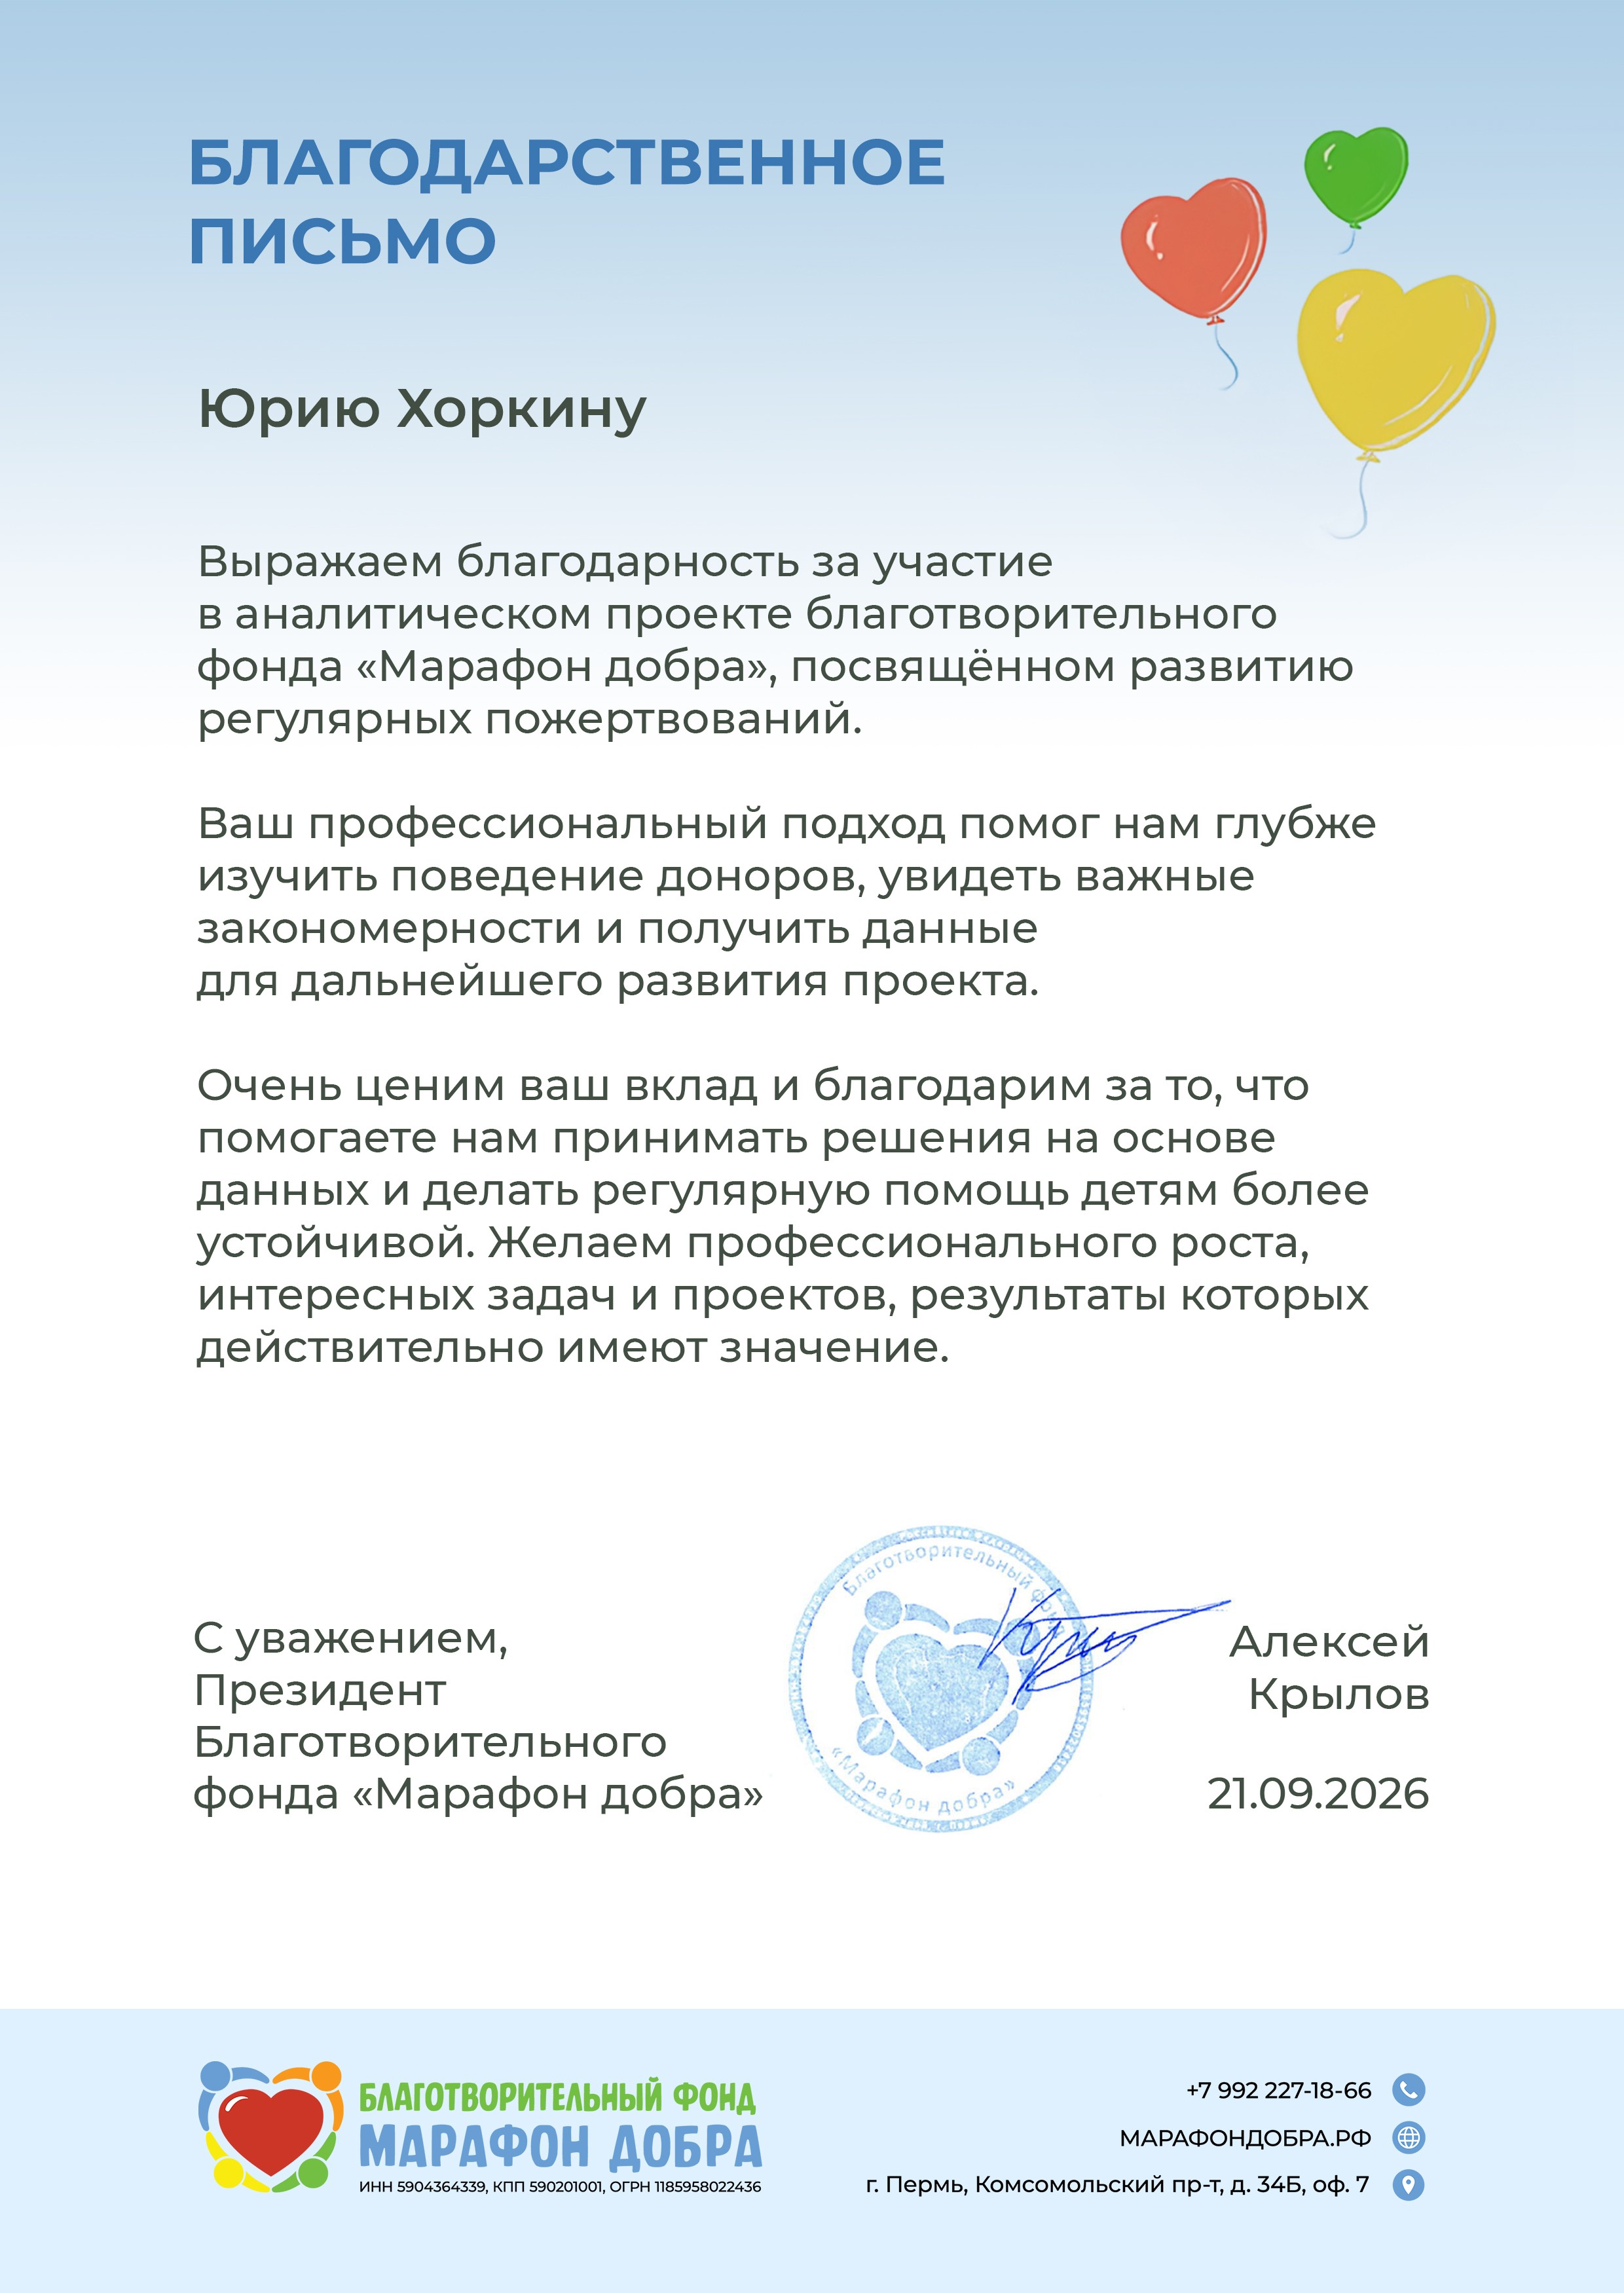

# Тема проекта

**Комплексный анализ платежей донаторов благотворительного фонда** с целью выявления факторов удержания, роста регулярных пожертвований и повышения эффективности работы с донаторами.

---

## Цель проекта

Провести аналитическое исследование исторических данных о пожертвованиях, определить ключевые закономерности поведения донаторов, оценить эффективность регулярных подписок и сформулировать практические рекомендации для увеличения объема регулярных пожертвований и удержания донаторов.

---

## Задачи исследования

1. **Выполнить исследовательский анализ данных (EDA)**, проверить качество данных, обработать пропуски и дубликаты, привести типы данных и сформировать аналитический датасет. 

2. **Рассчитать основные бизнес-показатели фонда:** 
    - количество донаторов; 
    - количество платежей; 
    - общий объем пожертвований; 
    - средний и медианный чек; 
    - среднюю сумму пожертвований по месяцам; 
    - число новых и активных донаторов. 

3. **Проанализировать динамику показателей во времени:** 
    - объем пожертвований; 
    - количество платежей; 
    - средний чек; 
    - сезонность; 
    - темпы роста. 

4. **Выполнить RFM-анализ и сегментировать донаторов** по давности последнего пожертвования (Recency), частоте пожертвований (Frequency) и суммарному объему пожертвований (Monetary). Описать характеристики каждого сегмента и предложить стратегии взаимодействия. 

5. **Провести когортный анализ по месяцу первого пожертвования.** Построить матрицу удержания (Retention Matrix), оценить удержание различных когорт и сравнить их жизненный цикл. 

6. **Исследовать подписки:**
    - долю регулярных пожертвований; 
    - среднюю длительность подписки; 
    - распределение срока жизни подписок; 
    - уровень оттока; 
    - среднее количество платежей на подписчика. 

7. **Провести Survival Analysis (анализ выживаемости подписок):**
    - построить кривую Каплана—Майера (Kaplan–Meier); 
    - определить вероятность сохранения подписки через 1, 3, 6, 12 месяцев; 
    - определить наиболее критичные периоды ухода донаторов; 
    - оценить медианное время жизни подписки. 

8. **Проанализировать переход пользователей от разовых пожертвований к регулярным подпискам** (при наличии соответствующих данных), определить конверсию и среднее время до перехода. 

9. **Рассчитать показатели:**
    - Retention; 
    - Churn Rate; 
    - Lifetime Value (LTV). 

10. **Выполнить ABC-анализ и Pareto-анализ**, определить вклад крупнейших донаторов в общий объем пожертвований. 

11. **Исследовать повторные пожертвования**, интервалы между платежами и жизненный цикл донатора. 
 
12. **Сформулировать практические рекомендации для фонда**, направленные на: 
    - увеличение регулярных пожертвований; 
    - повышение удержания донаторов; 
    - увеличение средней продолжительности подписки; 
    - рост долгосрочной ценности каждого донатора.

## Описание данных
**Столбцы** 
- "ID" - идентификатор подписки
- "Дата/время создания" - Когда была создана подсика
- "Статус" - Действует подписка или нет (статус "Активна" означает, что она работает)
- "Сумма" - сумма платежа по подписке
- "Валюта" - валюта оплаты подписки
- "Периодичность" - какой период списания у подписки 
- "Описание" - за какую услугу приобретена подписка
- "ID плательщика" - идентификатор плательщика
- "Кол-во платежей" - сколько было оплат по подписке
- "Дата/время последнего платежа" - когда был последний платёж по подписке 
- "Дата/время следующего платежа" - когда будет следующая оплата по подписке.

Если в столбце с количеством платежей количество платежей меньше количества месяцев в периоде, значит оплат не было последние месяцы.

## Исследовательский анализ данных 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import KaplanMeierFitter

<font color= #0210CF>Загрузим и посмотрим данные, добавим разделение по ";"</font>

In [2]:
donat_data = pd.read_csv('encoded_Подписки Cloud Payments 18-06.csv', sep=';', encoding='utf-8', on_bad_lines='warn')

In [3]:
# Сделаем функцию для отображения нужной информации
def info_sum(dataframe):
    display(dataframe.head(3))
    display(dataframe.tail(3))
    display(dataframe.info())

In [4]:
info_sum(donat_data)

,ID,Дата/время создания,Статус,Сумма,Валюта,Периодичность,Описание,ID плательщика,Кол-во платежей,Дата/время последнего платежа,Дата/время следующего платежа
0,sc_5fd0defafe7ff468dbd3257da445c,18.06.2026 08:39:25,Активна,"1000,00",₽,Раз в месяц,Благотворительное пожертвование. Ежемесячная п...,PID_41ef2e0fdbe2,0,NaN,18.07.2026 08:39:24
1,sc_fb4115049bb199106b401cb66c8bb,17.06.2026 20:57:39,Активна,"100,00",₽,Раз в месяц,Благотворительное пожертвование,PID_34f44fc59dc0,0,NaN,17.07.2026 20:57:39
2,sc_1dad551bda204a1c1ce3a60573458,17.06.2026 20:35:25,Активна,"100,00",₽,Раз в месяц,Благотворительное пожертвование,PID_1070551ebf1b,0,NaN,17.07.2026 20:35:25


,ID,Дата/время создания,Статус,Сумма,Валюта,Периодичность,Описание,ID плательщика,Кол-во платежей,Дата/время последнего платежа,Дата/время следующего платежа
42803,sc_dc145766ea9b91b3ab8f22af752b3,09.04.2019 20:23:42,Отклонена,"500,00",₽,Раз в месяц,Благотворительное пожертвование,PID_1cc3348ddcd0,1,09.05.2019 20:24:53,NaN
42804,sc_17fadc1d0d553006ffb4d35e42033,08.04.2019 18:46:12,Отклонена,"14,00",₽,Раз в месяц,Благотворительное пожертвование,PID_0afb888af63c,1,08.05.2019 18:49:57,NaN
42805,sc_f2effdb49d155978206a57f5c763a,08.04.2019 17:48:18,Отклонена,"100,00",₽,Раз в месяц,Благотворительное пожертвование,PID_058fbfa566c8,0,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42806 entries, 0 to 42805
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   ID                             42806 non-null  object
 1   Дата/время создания            42806 non-null  object
 2   Статус                         42806 non-null  object
 3   Сумма                          42806 non-null  object
 4   Валюта                         42806 non-null  object
 5   Периодичность                  42806 non-null  object
 6   Описание                       42806 non-null  object
 7   ID плательщика                 42806 non-null  object
 8   Кол-во платежей                42806 non-null  int64 
 9   Дата/время последнего платежа  28537 non-null  object
 10  Дата/время следующего платежа  6528 non-null   object
dtypes: int64(1), object(10)
memory usage: 3.6+ MB


None

### Предобработка данных

<font color= #0210CF>Переименуем столбцы для удобства работы, и приведем типы данных</font>

In [5]:
# Переименование через словарь для наглядности
df = donat_data.rename(columns={
    'ID': 'id',
    'Дата/время создания': 'created_at',
    'Статус': 'status',
    'Сумма': 'amount',
    'Валюта': 'currency',
    'Периодичность': 'frequency',
    'Описание': 'description',
    'ID плательщика': 'payer_id',
    'Кол-во платежей': 'payments_count',
    'Дата/время последнего платежа': 'last_payment_date',
    'Дата/время следующего платежа': 'next_payment_date'
})

# Преобразование всех дат в один цикл
date_columns = ['created_at', 'last_payment_date', 'next_payment_date']
for col in date_columns:
    df[col] = pd.to_datetime(df[col], format='%d.%m.%Y %H:%M:%S', errors='coerce')

# Преобразуем столбец с суммой, заменив запятую на точку
df['amount'] = df['amount'].str.replace(',', '.').astype(float)

# Преобразуем столбец с кол-вом платежей
df['payments_count'] = pd.to_numeric(df['payments_count'], errors='coerce').fillna(0).astype(int)

In [6]:
info_sum(df)

,id,created_at,status,amount,currency,frequency,description,payer_id,payments_count,last_payment_date,next_payment_date
0,sc_5fd0defafe7ff468dbd3257da445c,2026-06-18 08:39:25,Активна,1000.0,₽,Раз в месяц,Благотворительное пожертвование. Ежемесячная п...,PID_41ef2e0fdbe2,0,NaT,2026-07-18 08:39:24
1,sc_fb4115049bb199106b401cb66c8bb,2026-06-17 20:57:39,Активна,100.0,₽,Раз в месяц,Благотворительное пожертвование,PID_34f44fc59dc0,0,NaT,2026-07-17 20:57:39
2,sc_1dad551bda204a1c1ce3a60573458,2026-06-17 20:35:25,Активна,100.0,₽,Раз в месяц,Благотворительное пожертвование,PID_1070551ebf1b,0,NaT,2026-07-17 20:35:25


,id,created_at,status,amount,currency,frequency,description,payer_id,payments_count,last_payment_date,next_payment_date
42803,sc_dc145766ea9b91b3ab8f22af752b3,2019-04-09 20:23:42,Отклонена,500.0,₽,Раз в месяц,Благотворительное пожертвование,PID_1cc3348ddcd0,1,2019-05-09 20:24:53,NaT
42804,sc_17fadc1d0d553006ffb4d35e42033,2019-04-08 18:46:12,Отклонена,14.0,₽,Раз в месяц,Благотворительное пожертвование,PID_0afb888af63c,1,2019-05-08 18:49:57,NaT
42805,sc_f2effdb49d155978206a57f5c763a,2019-04-08 17:48:18,Отклонена,100.0,₽,Раз в месяц,Благотворительное пожертвование,PID_058fbfa566c8,0,NaT,NaT


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42806 entries, 0 to 42805
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 42806 non-null  object        
 1   created_at         42806 non-null  datetime64[ns]
 2   status             42806 non-null  object        
 3   amount             42806 non-null  float64       
 4   currency           42806 non-null  object        
 5   frequency          42806 non-null  object        
 6   description        42806 non-null  object        
 7   payer_id           42806 non-null  object        
 8   payments_count     42806 non-null  int32         
 9   last_payment_date  28537 non-null  datetime64[ns]
 10  next_payment_date  6528 non-null   datetime64[ns]
dtypes: datetime64[ns](3), float64(1), int32(1), object(6)
memory usage: 3.4+ MB


None

In [7]:
print('Пропуски:\n', df.isna().sum())
print('\nСтатусы:', df['status'].value_counts())
print('Валюта:', df['currency'].unique())
print('Периодичность:', df['frequency'].unique())
print('Временной срез:', df['created_at'].min(), '-', df['created_at'].max())

Пропуски:
 id                       0
created_at               0
status                   0
amount                   0
currency                 0
frequency                0
description              0
payer_id                 0
payments_count           0
last_payment_date    14269
next_payment_date    36278
dtype: int64

Статусы: status
Отменена      19259
Отклонена     17025
Активна        4827
Просрочена     1643
В ожидании       52
Name: count, dtype: int64
Валюта: ['₽']
Периодичность: ['Раз в месяц']
Временной срез: 2019-04-08 17:48:18 - 2026-06-18 08:39:25


<font color= #0210CF>**Промежуточные выводы:**<br>
Даты приведены к datetime64, суммы — к float.<br>
Столбец `payments_count` — целочисленный.<br>
Проверены пропуски: пропуски в столбцах `last_payment_date` и `next_payment_date` ожидаемы для подписок без платежей.<br>
Статусы: Активна, Просрочена, Отклонена, Отменена, Завершена, В ожидании.
</font>

<font color= #0210CF>Теперь проверим наличие явных и неявных дубликатов, а также выбросы.</font>

In [8]:
# Посмотрим явные дубликаты
display(df.duplicated().sum())

# Проверить дубликаты по ID (их быть не должно)
display(df['id'].duplicated().sum())

# Посмотрим неявные дубликаты в связки заказа и даты последнего платежа
display(df.duplicated(subset= ['id', 'last_payment_date']).sum())

# По payer_id + amount + datetime_created (возможные дубликаты платежей)
display(df.duplicated(subset=['payer_id', 'amount', 'created_at']).sum())

# По payer_id + datetime_created (один плательщик не может создать 2 платежа в одно время)
display(df.duplicated(subset=['payer_id', 'created_at']).sum())

0

0

0

0

0

<font color=  #0210CF> **Промежуточные выводы:**<br>
Явных и неявных дубликатов нет.
</font>

<font color=  #0210CF> Проверим количество подписок на пользователя

In [9]:
df.groupby('payer_id')['id'].count().sort_values(ascending=False)

payer_id
PID_6d37612512a5    300
PID_8511f2b72b8e    219
PID_72088c7d14b8    116
PID_5e5e0d59a806     51
PID_9c4d96807f9a     51
                   ... 
PID_5e114b6ca082      1
PID_5e0dcdcc9ccf      1
PID_5e0d8f3047e9      1
PID_5e04b1e43a43      1
PID_ffff99b358f1      1
Name: id, Length: 31105, dtype: int64

<font color=  #0210CF> Есть "чемпионы", посмотрим кто они

In [10]:
# Сделаем формулу для вывода информации
def info_payer(dataframe):
    display(dataframe.head(3))
    
    print('Статусы:')
    print(dataframe['status'].value_counts(dropna=False))
    
    print('Суммы и их количество:')
    print(dataframe['amount'].value_counts(dropna=False))

In [11]:
info_payer(df[df['payer_id'] == 'PID_6d37612512a5'])

,id,created_at,status,amount,currency,frequency,description,payer_id,payments_count,last_payment_date,next_payment_date
6139,sc_0e8498019f83d1b930f55db8c44af,2024-10-15 09:41:04,Отклонена,40.00,₽,Раз в месяц,Благотворительное пожертвование. Ежемесячная п...,PID_6d37612512a5,0,NaT,NaT
6192,sc_642e6f12fca7a057f90828b7824c0,2024-10-12 18:04:32,Отклонена,1.99,₽,Раз в месяц,Благотворительное пожертвование. Ежемесячная п...,PID_6d37612512a5,0,NaT,NaT
6193,sc_53bcf301a8476ec2d6c484509e24f,2024-10-12 18:03:54,Отклонена,1.99,₽,Раз в месяц,Благотворительное пожертвование. Ежемесячная п...,PID_6d37612512a5,0,NaT,NaT


Статусы:
status
Отклонена    300
Name: count, dtype: int64
Суммы и их количество:
amount
1.99     298
40.00      1
1.05       1
Name: count, dtype: int64


<font color=  #0210CF>Все платежи отклонены, почти все на одну и ту же сумму - похож на тестовый аккаунт (со слов заказчика так и есть), исключим его в дальнейшим.<br>
Посмотрим других "чемпионов"
</font>

In [12]:
info_payer(df[df['payer_id'] == 'PID_8511f2b72b8e'])

,id,created_at,status,amount,currency,frequency,description,payer_id,payments_count,last_payment_date,next_payment_date
67,sc_9d225c7e07817cbcba200779c05aa,2026-05-30 12:34:16,Активна,51.0,₽,Раз в месяц,Благотворительное пожертвование. Ежемесячная п...,PID_8511f2b72b8e,0,NaT,2026-06-30 12:34:16
91,sc_19f5ca134bc1022cd41cca96e6cbd,2026-05-21 13:51:39,Активна,78.0,₽,Раз в месяц,Благотворительное пожертвование. Ежемесячная п...,PID_8511f2b72b8e,0,NaT,2026-06-21 13:51:39
92,sc_c3b9a251d6e6fa3bc2484079b9d5c,2026-05-21 13:50:10,Активна,90.0,₽,Раз в месяц,Благотворительное пожертвование. Ежемесячная п...,PID_8511f2b72b8e,0,NaT,2026-06-21 13:50:09


Статусы:
status
Активна       177
Отклонена      41
Просрочена      1
Name: count, dtype: int64
Суммы и их количество:
amount
77.0     9
90.0     8
89.0     8
67.0     8
78.0     7
99.0     7
79.0     7
103.0    7
66.0     7
75.0     6
87.0     6
60.0     6
71.0     6
68.0     6
74.0     6
88.0     5
76.0     5
62.0     5
65.0     5
70.0     5
69.0     5
80.0     5
63.0     5
61.0     5
73.0     4
64.0     4
72.0     4
50.0     4
55.0     3
45.0     3
44.0     3
35.0     3
86.0     3
91.0     3
58.0     3
81.0     3
38.0     2
82.0     2
51.0     2
83.0     2
92.0     2
95.0     2
85.0     2
97.0     1
57.0     1
54.0     1
47.0     1
84.0     1
40.0     1
94.0     1
102.0    1
105.0    1
98.0     1
104.0    1
100.0    1
109.0    1
93.0     1
101.0    1
48.0     1
Name: count, dtype: int64


<font color=  #0210CF>А этот не похож на тестовый аккаунт - платежи на разные суммы и большинство подписок активна<br>
Посмотрим сколько у него было платежей на подписках:
</font>

In [13]:
df[df['payer_id'] == 'PID_8511f2b72b8e']['payments_count'].unique()

array([0, 1, 2, 3, 4])

<font color=  #0210CF>Этого "чемпиона" оставим, он реальный плательщик, видимо были какие-то причины, почему он завел такое кол-во подписок, проблемы с интерфейсом или еще что.<br>
Пострим еще одного, с 116 подписками:
</font>

In [14]:
info_payer(df[df['payer_id'] == 'PID_72088c7d14b8'])

,id,created_at,status,amount,currency,frequency,description,payer_id,payments_count,last_payment_date,next_payment_date
7869,sc_071d642c2dde94a208e9510783b4f,2024-07-09 10:38:17,Просрочена,17.0,₽,Раз в месяц,Благотворительное пожертвование,PID_72088c7d14b8,13,2026-05-11 10:40:59,2026-07-09 10:38:17
8737,sc_900bf0bc5879160a23f241d975f4f,2024-06-03 16:54:13,Просрочена,17.0,₽,Раз в месяц,Благотворительное пожертвование,PID_72088c7d14b8,12,2025-09-03 16:54:50,2026-07-03 16:54:13
8821,sc_ff0bdfc43da5bd38cdde101b128c0,2024-05-30 23:43:38,Просрочена,17.0,₽,Раз в месяц,Благотворительное пожертвование,PID_72088c7d14b8,12,2026-03-30 23:44:15,2026-06-30 23:43:38


Статусы:
status
Просрочена    103
Активна         7
Отклонена       6
Name: count, dtype: int64
Суммы и их количество:
amount
17.0    115
15.0      1
Name: count, dtype: int64


<font color=  #0210CF>И еще одного, с 51 подпиской:
</font>

In [15]:
info_payer(df[df['payer_id'] == 'PID_5e5e0d59a806'])

,id,created_at,status,amount,currency,frequency,description,payer_id,payments_count,last_payment_date,next_payment_date
2323,sc_663c7f76451edbcafc96f77bd3476,2025-06-25 14:28:56,Активна,1000.0,₽,Раз в месяц,Благотворительное пожертвование,PID_5e5e0d59a806,11,2026-05-26 14:31:10,2026-06-25 14:28:56
7785,sc_435fdf480e541f2c23038c1e4a3fa,2024-07-17 21:10:01,Активна,500.0,₽,Раз в месяц,Благотворительное пожертвование,PID_5e5e0d59a806,23,2026-06-17 21:11:27,2026-07-17 21:10:01
7789,sc_dd2259a3b2a2de10adea5b7732b98,2024-07-17 16:31:04,Активна,500.0,₽,Раз в месяц,Благотворительное пожертвование,PID_5e5e0d59a806,23,2026-06-17 16:32:27,2026-07-17 16:31:04


Статусы:
status
Отклонена     40
Активна        6
Просрочена     5
Name: count, dtype: int64
Суммы и их количество:
amount
500.0     47
1000.0     3
200.0      1
Name: count, dtype: int64


<font color=  #0210CF>Последних двоих исключать не будем.<br>
**Промежуточные выводы**: выявился недостаток данных - для каждой подписки отражен только одни платеж, хотя по ней было несколько платежей. Для аналитического датасета потребуется реконструкция ежемесячных платежей.
</font>

<font color=  #0210CF>Теперь посмотрим распределение значений в столбце Сумма и наличие выбросов:
</font>

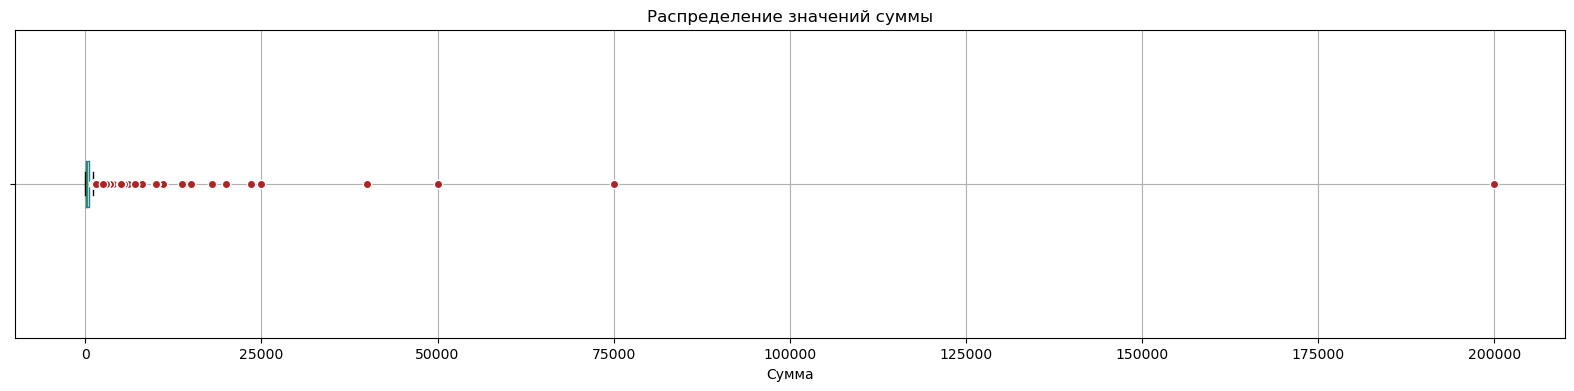

In [16]:
# Проверим наличие выбросов в столбце amount
plt.figure(figsize=(20, 4))
df.boxplot(column='amount', vert=False, flierprops=dict(markerfacecolor='firebrick', marker='o', markeredgecolor='white'))
plt.title('Распределение значений суммы')
plt.xlabel('Сумма')
plt.gca().set_yticklabels([])
plt.show()

<font color=  #0210CF>Выбросы явно есть, учтем их отдельным сегментом (пожелание заказчика)
</font>

### Очистка от тестовых записей и обработка дат

In [17]:
# Исключаем тестовые записи
# 1) Верификационные платежи ровно по 1.99 ₽
mask_test_amount = df['amount'] == 1.99

# 2) Тестовый плательщик с 300 подписками
payer_counts = df['payer_id'].value_counts()
test_payers = payer_counts[payer_counts >= 300].index.tolist()
mask_test_payer = df['payer_id'].isin(test_payers)

print(f'Исключено тестовых платежей 1.99₽: {mask_test_amount.sum()}')
print(f'Исключено тестовых плательщиков: {len(test_payers)}, строк: {mask_test_payer.sum()}')

df_clean = df[~mask_test_amount & ~mask_test_payer].copy()
print('Форма датасета после очистки:', df_clean.shape)

# --- Обработка пропусков в датах ---
# Если платежей не было, считаем окончанием жизни дату создания
df_clean['last_payment_date'] = df_clean['last_payment_date'].fillna(df_clean['created_at'])

# --- Выделение крупных донаторов отдельным сегментом (большей или равной сумме 10000) ---
HIGH_AMOUNT_THRESHOLD = 10000  # ₽/мес
df_high = df_clean[df_clean['amount'] >= HIGH_AMOUNT_THRESHOLD].copy()   # отдельный сегмент
df_main = df_clean[df_clean['amount'] < HIGH_AMOUNT_THRESHOLD].copy()    # для средних показателей
print(f'Крупные подписки (>= {HIGH_AMOUNT_THRESHOLD}₽): {len(df_high)}')

Исключено тестовых платежей 1.99₽: 309
Исключено тестовых плательщиков: 1, строк: 300
Форма датасета после очистки: (42495, 11)
Крупные подписки (>= 10000₽): 51


<font color=  #0210CF>**Промежуточные выводы:**<br>
Удалены тестовые платежи по 1.99 ₽ и тестовый плательщик с аномальным числом подписок.<br>
Для подписок без платежей дата окончания приравнена к дате создания.<br>
Крупные донаторы (≥10 000 ₽/мес) выделены в отдельный сегмент, чтобы не искажать средние показатели. Для Парето-анализа они будут возвращены.
</font>

### Формирование аналитического датасета

Реконструкция ежемесячных платежей на основе Бизнес-правила, подтвержденного заказчиком.<br>
Платежи внутри подписки проходят последовательно с момента её создания, если число платежей меньше числа прошедших месяцев, неоплаченными являются именно последние месяцы.<br>
На основании этого правила восстановлены месяцы успешных платежей.

In [18]:
# Точка среза (дата выгрузки)
SNAPSHOT_DATE = pd.Timestamp('2026-06-18')

# === Контрольные проверки ===
assert df_clean['id'].is_unique, 'Обнаружены дубликаты по id'
assert (df_clean['payments_count'] >= 0).all(), 'Отрицательные платежи'

# # Реконструкция ежемесячных платежей (для корректной динамики по месяцам)

tmp = df_clean[df_clean['payments_count'] > 0].copy()
tmp['start_period'] = tmp['created_at'].dt.to_period('M')
tmp['month_offset'] = tmp['payments_count'].apply(lambda n: list(range(n)))

payments_df = tmp.explode('month_offset')
payments_df['month_offset'] = payments_df['month_offset'].astype(int)
payments_df['payment_period'] = payments_df['start_period'] + payments_df['month_offset']
payments_df['payment_month'] = payments_df['payment_period'].dt.to_timestamp()
payments_df = payments_df[['payer_id', 'amount', 'payment_month', 'payment_period']].reset_index(drop=True)

print('Реконструировано платежей:', len(payments_df))
assert len(payments_df) == df_clean['payments_count'].sum(), 'Несовпадение числа реконструированных платежей'

# === Проверка реконструкции ===
# Ожидаемый последний месяц = месяц создания + число платежей - 1
mask_has_payments = df_clean['payments_count'] > 0
expected_last_period = (
    df_clean.loc[mask_has_payments, 'created_at'].dt.to_period('M')
    + df_clean.loc[mask_has_payments, 'payments_count'] - 1
)
actual_last_period = df_clean.loc[mask_has_payments, 'last_payment_date'].dt.to_period('M')

mismatch_count = (expected_last_period != actual_last_period).sum()
total_checked = mask_has_payments.sum()
print(f'Проверка реконструкции: совпадают {total_checked - mismatch_count} из {total_checked} подписок')
if mismatch_count > 0:
    print(f'Расхождений: {mismatch_count} — требуют отдельного исследования')

# === Признаки подписки ===
df_clean['total_volume'] = df_clean['amount'] * df_clean['payments_count']
df_clean['cohort'] = df_clean['created_at'].dt.to_period('M')

# Признак события (оттока) для анализа выживаемости
# Просрочена, Активна, В ожидании -> цензурировано (0)
# Отменена, Отклонена, Завершена -> событие (1)
churn_statuses = ['Отменена', 'Отклонена', 'Завершена']
df_clean['event'] = df_clean['status'].isin(churn_statuses).astype(int)

# === Длительность жизни подписки ===
# Разделяем два показателя:
# 1) Время успешных платежей: created_at -> last_payment_date
# 2) Время жизни подписки как объекта: created_at -> терминальный статус / SNAPSHOT_DATE

# Для терминальных подписок конец = дата последнего платежа
end_date_churned = df_clean['last_payment_date']

# Для живых (цензурированных) подписок конец = SNAPSHOT_DATE
end_date_censored = pd.Series(SNAPSHOT_DATE, index=df_clean.index)

df_clean['end_date'] = end_date_churned.where(df_clean['event'] == 1, end_date_censored)
df_clean['end_date'] = df_clean['end_date'].clip(upper=SNAPSHOT_DATE)

# Время жизни подписки как объекта
df_clean['duration_months'] = (
    (df_clean['end_date'] - df_clean['created_at']).dt.days / 30.44
).clip(lower=0)

# Время успешных платежей (отдельный показатель)
df_clean['payment_duration_months'] = (
    (df_clean['last_payment_date'] - df_clean['created_at']).dt.days / 30.44
).clip(lower=0)

# === Метрика пропущенных месяцев ===
df_clean['months_elapsed'] = (
    (SNAPSHOT_DATE - df_clean['created_at']).dt.days / 30.44
).clip(lower=0)
df_clean['months_missed'] = (df_clean['months_elapsed'] - df_clean['payments_count']).clip(lower=0)

# === Сегментация по пропущенным месяцам ===
def missed_segment(m):
    if m == 0:
        return '0 пропусков (регулярно)'
    elif m <= 1:
        return '1 пропуск (первый риск)'
    elif m <= 2:
        return '2 пропуска (высокий риск)'
    else:
        return '3+ пропуска (вероятный отток)'

df_clean['missed_segment'] = df_clean['months_missed'].apply(missed_segment)

print('Форма датасета после очистки:', df_clean.shape)
print('\nСегментация по пропущенным месяцам:')
print(df_clean['missed_segment'].value_counts())

df_clean[['id', 'created_at', 'status', 'amount', 'payments_count',
          'total_volume', 'cohort', 'event', 'duration_months',
          'payment_duration_months', 'months_missed', 'missed_segment']].head()

Реконструировано платежей: 238277
Проверка реконструкции: совпадают 21 из 28537 подписок
Расхождений: 28516 — требуют отдельного исследования
Форма датасета после очистки: (42495, 20)

Сегментация по пропущенным месяцам:
missed_segment
3+ пропуска (вероятный отток)    38420
1 пропуск (первый риск)           3139
2 пропуска (высокий риск)          758
0 пропусков (регулярно)            178
Name: count, dtype: int64


,id,created_at,status,amount,payments_count,total_volume,cohort,event,duration_months,payment_duration_months,months_missed,missed_segment
0,sc_5fd0defafe7ff468dbd3257da445c,2026-06-18 08:39:25,Активна,1000.0,0,0.0,2026-06,0,0.000000,0.0,0.000000,0 пропусков (регулярно)
1,sc_fb4115049bb199106b401cb66c8bb,2026-06-17 20:57:39,Активна,100.0,0,0.0,2026-06,0,0.000000,0.0,0.000000,0 пропусков (регулярно)
2,sc_1dad551bda204a1c1ce3a60573458,2026-06-17 20:35:25,Активна,100.0,0,0.0,2026-06,0,0.000000,0.0,0.000000,0 пропусков (регулярно)
3,sc_9c512c6a7880f7cceb309c654c7ef,2026-06-16 20:37:05,Активна,500.0,0,0.0,2026-06,0,0.032852,0.0,0.032852,1 пропуск (первый риск)
4,sc_b1911b7fb5bd247c6c40f25707aed,2026-06-16 15:43:23,Активна,100.0,0,0.0,2026-06,0,0.032852,0.0,0.032852,1 пропуск (первый риск)


<font color=  #0210CF>**Промежуточные выводы**
Реконструированы ежемесячные платежи (датасет `payments_df`): каждое успешное списание разнесено по месяцам для корректности динамики и среднего числа платежей по месяцам.<br>
Добавлены признаки: `total_volume` (объём подписки), `cohort` (месяц первого платежа), `event` (флаг оттока), `duration_months` (срок жизни в месяцах), `payment_duration_months`(срок жизни успешных платежей), `months_missed` (метрика пропущенных месяцев), `missed_segment` (сегментация по пропущенным месяцам).<br>
Логика оттока согласно пояснениям от заказчика: Просрочена/Активна/В ожидании — подписка жива (цензурировано), Отменена/Отклонена/Завершена — событие, подписка утрачена.
</font>

## Основные бизнес-показатели фонда

In [19]:
# Количество донаторов
unique_donors = df_clean['payer_id'].nunique()

# Количество платежей (успешных списаний)
total_payments = int(df_clean['payments_count'].sum())

# Общий объем пожертвований
total_donations = df_clean['total_volume'].sum()

# Средний и медианный чек (по всем и отдельно по крупному сегменту)
avg_check_all = total_donations / total_payments if total_payments else 0
median_check_all = df_clean.loc[df_clean['payments_count'] > 0, 'amount'].median()

avg_check_main = df_main.loc[df_main['payments_count'] > 0, 'amount'].mean()
median_check_main = df_main.loc[df_main['payments_count'] > 0, 'amount'].median()
avg_check_high = df_high.loc[df_high['payments_count'] > 0, 'amount'].mean() if len(df_high) else 0

# Средняя сумма пожертвований по месяцам
monthly_amount = payments_df.groupby('payment_month')['amount'].agg(['sum', 'count', 'mean'])
monthly_amount.columns = ['donations_volume', 'payments_count', 'avg_donation']

# Число новых и активных донаторов
first_cohort = df_clean[df_clean['payments_count'] > 0].groupby('payer_id')['cohort'].min().reset_index()
first_cohort.columns = ['payer_id', 'first_cohort']
new_donors_by_month = first_cohort.groupby('first_cohort')['payer_id'].nunique()

active_donors = df_clean[(df_clean['status'] == 'Активна')]['payer_id'].nunique()

**Бизнес-показатели за весь период:**

In [20]:
print(f'Уникальных донаторов: {unique_donors:,}'.replace(',', ' '))
print(f'Всего успешных платежей: {total_payments:,}'.replace(',', ' '))
print(f'Общий объем пожертвований: {total_donations:,.2f} ₽'.replace(',', ' '))
print(f' Средний чек (все): {avg_check_all:,.2f} ₽'.replace(',', ' '))
print(f' Медианный чек (все): {median_check_all:,.2f} ₽'.replace(',', ' '))
print(f' Средний чек (основной сегмент): {avg_check_main:,.2f} ₽'.replace(',', ' '))
print(f' Медианный чек (основной сегмент):{median_check_main:,.2f} ₽'.replace(',', ' '))
print(f' Средний чек (крупный сегмент): {avg_check_high:,.2f} ₽'.replace(',', ' '))
print(f'Активных донаторов: {active_donors:,}'.replace(',', ' '))

Уникальных донаторов: 31 104
Всего успешных платежей: 238 277
Общий объем пожертвований: 74 129 253.82 ₽
 Средний чек (все): 311.11 ₽
 Медианный чек (все): 200.00 ₽
 Средний чек (основной сегмент): 319.06 ₽
 Медианный чек (основной сегмент):200.00 ₽
 Средний чек (крупный сегмент): 12 421.74 ₽
Активных донаторов: 4 176


**Средняя сумма по месяцам:**

In [21]:
with pd.option_context('display.max_rows', None):
    display(monthly_amount.reset_index())

,payment_month,donations_volume,payments_count,avg_donation
0,2019-04-01,75714.00,279,271.376344
1,2019-05-01,98933.00,401,246.715711
2,2019-06-01,114710.00,443,258.939052
3,2019-07-01,156005.00,614,254.079805
4,2019-08-01,152098.00,603,252.235489
5,2019-09-01,136947.00,579,236.523316
6,2019-10-01,130315.00,564,231.054965
7,2019-11-01,135377.00,587,230.625213
8,2019-12-01,161268.00,679,237.508100
9,2020-01-01,157957.00,693,227.932179


**Новые донаторы по месяцам:**

In [22]:
with pd.option_context('display.max_rows', None):
    display(new_donors_by_month.reset_index())

,first_cohort,payer_id
0,2019-04,258
1,2019-05,203
2,2019-06,163
3,2019-07,273
4,2019-08,158
5,2019-09,138
6,2019-10,98
7,2019-11,109
8,2019-12,178
9,2020-01,158


<font color=  #0210CF>**Промежуточные выводы**<br>
Посчитаны все показатели за весь период.<br>
Средний чек заметно выше медианного — распределение скошено вправо из-за крупных донаторов, поэтому крупный сегмент вынесен отдельно.<br>
Средний чек по месяцам (`avg_donation`) имеет тенденцию к увеличению, более наглядно будет при исследовании показателей во времени.<br>
Число новых донаторов по месяцам отражает месяцы первых оформлений подписок, допуская, что первое списание происходит при оформлении подписки.<br>
Для понимание тенденции посмотрим при изучение показателей во времени. <br>
</font>

## Динамика показателей во времени

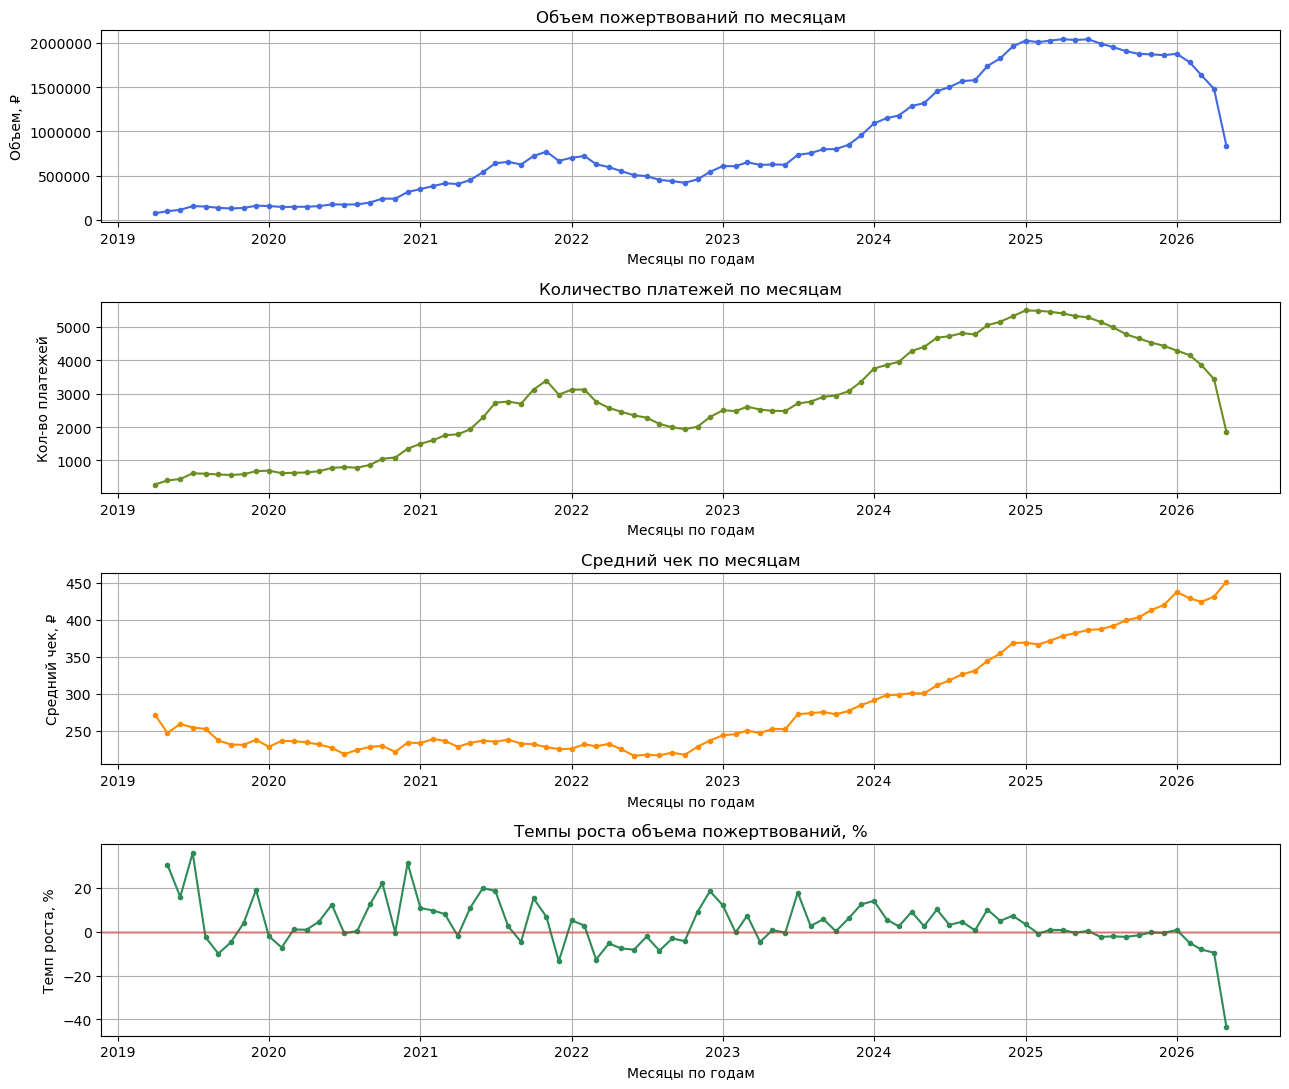

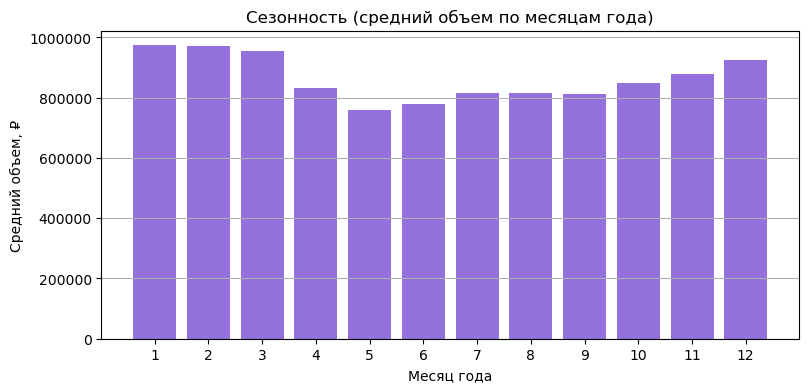

In [23]:
# Объем, количество платежей, средний чек по месяцам, последний месяц не учитываем
dynamics = monthly_amount.copy()

# Сезонность и темпы роста
dynamics['volume_growth'] = dynamics['donations_volume'].pct_change() * 100
dynamics['payments_growth'] = dynamics['payments_count'].pct_change() * 100
dynamics['month_num'] = dynamics.index.month
seasonality = dynamics.groupby('month_num')['donations_volume'].mean()

fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)

# Объем пожертвований
axes[0].plot(dynamics.index, dynamics['donations_volume'], marker='o', ms=3, color='royalblue')
axes[0].set_ylabel('Объем, ₽')
axes[0].set_xlabel('Месяцы по годам')
axes[0].set_title('Объем пожертвований по месяцам')
axes[0].ticklabel_format(style='plain', axis='y')
axes[0].tick_params(labelbottom=True)
axes[0].grid()

# Количество платежей
axes[1].plot(dynamics.index, dynamics['payments_count'], marker='o', ms=3, color='olivedrab')
axes[1].set_ylabel('Кол-во платежей')
axes[1].set_xlabel('Месяцы по годам')
axes[1].set_title('Количество платежей по месяцам')
axes[1].tick_params(labelbottom=True)
axes[1].grid()

# Средний чек
axes[2].plot(dynamics.index, dynamics['avg_donation'], marker='o', ms=3, color='darkorange')
axes[2].set_ylabel('Средний чек, ₽')
axes[2].set_xlabel('Месяцы по годам')
axes[2].set_title('Средний чек по месяцам')
axes[2].tick_params(labelbottom=True)
axes[2].grid()

# Темпы роста
axes[3].plot(dynamics.index, dynamics['volume_growth'], marker='o', ms=3, color='seagreen')
axes[3].set_ylabel('Темп роста, %')
axes[3].set_xlabel('Месяцы по годам')
axes[3].set_title('Темпы роста объема пожертвований, %')
axes[3].grid()
axes[3].axhline(y=0, color='red', linestyle='-', alpha=0.3, linewidth=2)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(seasonality.index, seasonality.values, color='mediumpurple')
ax.set_xlabel('Месяц года')
ax.set_ylabel('Средний объем, ₽')
ax.set_title('Сезонность (средний объем по месяцам года)')
ax.set_xticks(range(1, 13))
ax.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y')
plt.show()

<font color=  #0210CF>**Промежуточные выводы (динамика показателей во времени)**
- Динамика объёма и числа платежей повторяет рост/спад активной базы подписок: плавный спад с 2025 года и усилившийся в 2026 году.
- В тоже время, средний чек демонстрирует тенденцию к росту, заметной со второй половины 2023 года: рост объёма поддерживается не только базой, но и чеком.
- **Сезонность:** Видны пики в начале/конце года (годовые пожертвования) и просадки в летний период, особенно в мае - июне. Рекомендация: планировать кампании привлечения перед пиками и удерживающие активности в периоды просадок.
- **Темпы роста:** Отрицательные значения указывают на месяцы спада, начиная с 25 года держится около нуля, в 26 году демонстрирует уверенный спад в отрицательную зону. Причины сопоставлены с оттоком и снижением притока новых донаторов.
</font>

## RFM-анализ донаторов

Для **Recency** здесь используем абсолютные сроки (нас интересуют пользователи, с которыми фонд взаимодействовал за прошедший год).
- 0–60 дней    → свежие / активные
- 61–180 дней  → под риском
- более 180 дней    → спящие
<br>

Для **Frequency** будем использовать следующее разделение:
- 1 платеж
- 2–6 платежей
- 7+ платежей

In [24]:
# Берем только донаторов с хотя бы одним успешным платежом
rfm_src = df_clean[df_clean['payments_count'] > 0]

rfm = rfm_src.groupby('payer_id').agg(
    recency=('last_payment_date', lambda x: (SNAPSHOT_DATE - x.max()).days),
    frequency=('payments_count', 'sum'),
    monetary=('total_volume', 'sum')
).reset_index()

# === Скоринг Recency по бизнес-порогам ===
def r_score(days):
    if days <= 60:
        return 3   # свежие / активные
    elif days <= 180:
        return 2   # под риском
    else:
        return 1   # спящие

rfm['r_score'] = rfm['recency'].apply(r_score)

# === Скоринг Frequency по понятным интервалам ===
def f_score(freq):
    if freq >= 7:
        return 3
    elif freq >= 2:
        return 2
    else:
        return 1

rfm['f_score'] = rfm['frequency'].apply(f_score)

# === Скоринг Monetary через квантили (без изменений) ===
rfm['m_score'] = pd.qcut(rfm['monetary'], 3, labels=[1, 2, 3], duplicates='drop').astype(int)

rfm['rfm_segment'] = rfm['r_score'].astype(str) + rfm['f_score'].astype(str) + rfm['m_score'].astype(str)

In [25]:
def classify_rfm(row):
    # 1. Чемпионы: свежие (<=60 дней) и частые (7+ платежей)
    if row['r_score'] == 3 and row['f_score'] == 3:
        return 'Чемпионы'
    # 2. Новые: свежие (<=60 дней) и нечастые (1-6 платежей)
    if row['r_score'] == 3 and row['f_score'] <= 2:
        return 'Новые'
    # 3. Уходящие ценные: не свежие (>60 дней) но частые или крупные
    if row['r_score'] <= 2 and (row['f_score'] >= 2 or row['m_score'] == 3):
        return 'Уходящие ценные'
    # 4. Спящие: давно не платили, редкие и небольшие
    return 'Спящие'

rfm['segment_name'] = rfm.apply(classify_rfm, axis=1)

segment_summary = rfm.groupby('segment_name').agg(
    donors=('payer_id', 'count'),
    avg_recency=('recency', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_monetary=('monetary', 'mean'),
    total_monetary=('monetary', 'sum')
).sort_values('total_monetary', ascending=False)

segment_summary['donors_share'] = segment_summary['donors'] / segment_summary['donors'].sum()
segment_summary['volume_share'] = segment_summary['total_monetary'] / segment_summary['total_monetary'].sum()

**Сводная таблица по 4 ключевым сегментам:**

In [26]:
display(segment_summary)

,donors,avg_recency,avg_frequency,avg_monetary,total_monetary,donors_share,volume_share
segment_name,,,,,,,
Чемпионы,3831,16.514226,29.737405,10049.562777,38499875.00,0.175220,0.519361
Уходящие ценные,12087,1168.893605,9.644329,2681.696120,32413661.00,0.552827,0.437259
Спящие,5231,1493.328618,1.000000,307.940130,1610834.82,0.239252,0.021730
Новые,715,18.988811,3.567832,2244.591608,1604883.00,0.032702,0.021650


<font color=  #0210CF>**Промежуточные выводы (RFM-анализ)**

Донаторы сегментированы по Recency / Frequency / Monetary на четыре ключевых сегмента (бизнес-пороги: Recency ≤ 60 / 61–180 / > 180 дней; Frequency 1 / 2–6 / 7+ платежей).

| Сегмент | Донаторов | Доля донаторов | Доля объёма | Интерпретация |
|---|---:|---:|---:|---|
| Чемпионы | 3 831 | ~17,5% | ~52% | Свежие, частые, крупные — ядро фонда |
| Уходящие ценные | 12 087 | ~55,3% | ~44% | Давно не активны, но с ценной историей — главный резерв реактивации |
| Спящие | 5 231 | ~23,9% | ~2% | Давно не активны, единичные небольшие платежи |
| Новые | 715 | ~3,3% | ~2% | Платили за последние 60 дней, начало пути |

- **Главный инсайт:** более половины платящей базы (55%) — «Уходящие ценные»: донаторы с наработанной историей платежей, давно не совершавшие списаний. Это крупнейший резерв возврата объёма через реактивацию (обновление карты, возврат к автоплатежу).
- **Чемпионы** (17,5% донаторов) обеспечивают около половины объёма — приоритет удержания и персональной коммуникации.
- **Новых** всего 3,3% — низкий приток свежих донаторов на фоне спада динамики 2026 года; усиливает приоритет привлечения и welcome-цепочки.

| Сегмент | RFM-профиль | Рекомендация |
|---|---|---|
| Чемпионы | Высокий R, высокий F, высокий M | Удержание и признание: персональные отчёты, клуб доноров, благодарности |
| Новые | Высокий R, низкий F | Welcome-цепочка, объяснение механики автоплатежа, рассказ о результате первой помощи |
| Уходящие ценные | Низкий R, высокий F или высокий M | Реактивация: письмо с просьбой обновить карту, опрос причины отмены, персональное обращение |
| Спящие | Низкий R, низкий F, низкий M | Win-back рассылки, адресные сборы с понятной целью и небольшой суммой входа |
</font>

| Сегмент | RFM-профиль | Интерпретация | Рекомендация |
|---|---|---|---|
| **Чемпионы** | Высокий R, высокий F, высокий M | Ядро фонда: платят недавно, часто и вносят основной вклад | Удержание и признание: персональные отчёты, клуб доноров, благодарности |
| **Новые** | Высокий R, низкий F | Недавно оформили подписку, совершили 1–2 платежа | Welcome-цепочка, объяснение механики автоплатежа, рассказ о результате первой помощи |
| **Уходящие ценные** | Низкий R, высокий F или высокий M | Раньше платили часто или крупно, сейчас давно не активны | Реактивация: письмо с просьбой обновить карту, опрос причины отмены, персональное обращение |
| **Спящие** | Низкий R, низкий F, низкий M | Давно не платили, платежи редкие и небольшие | Win-back рассылки, адресные сборы с понятной целью и небольшой суммой входа |

## Когортный анализ — матрица удержания

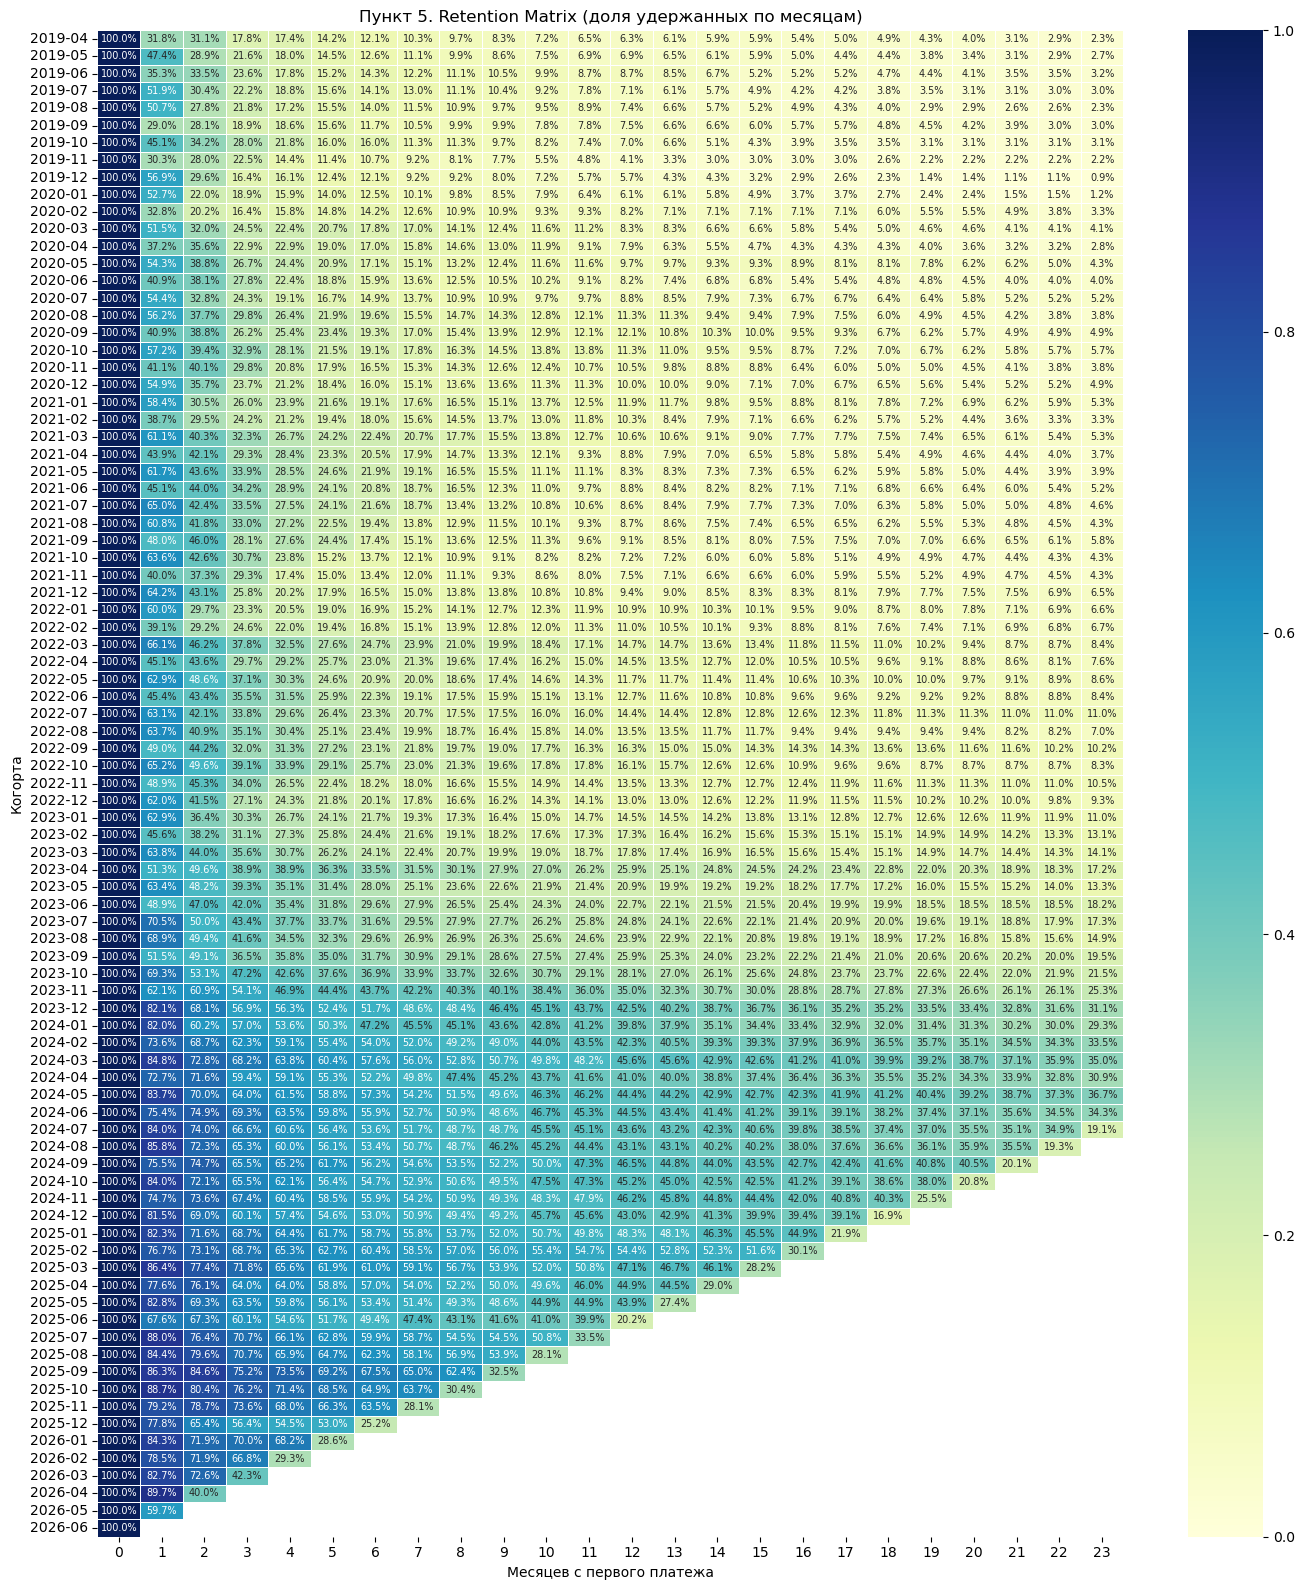

In [27]:
cohorts = sorted(df_clean['cohort'].unique())
max_k = int(np.floor(df_clean['duration_months'].max()))
k_range = np.arange(0, max_k + 1)

matrix = np.zeros((len(cohorts), len(k_range)))
for i, cohort in enumerate(cohorts):
    durations = df_clean.loc[df_clean['cohort'] == cohort, 'duration_months'].values
    for j, k in enumerate(k_range):
        matrix[i, j] = (durations >= k).mean()

retention_matrix = pd.DataFrame(matrix, index=pd.PeriodIndex(cohorts), columns=k_range)
retention_matrix.index.name = 'cohort'
retention_matrix.columns.name = 'month'

# === Маскировка молодых когорт ===
# Для каждого месяца удержания считаем значение только для когорт,
# которые успели прожить минимум столько месяцев на дату выгрузки.
for j, k in enumerate(k_range):
    cohort_min_date = pd.PeriodIndex(cohorts) + k  # минимальная дата, когда когорта проживёт k месяцев
    mask = cohort_min_date > SNAPSHOT_DATE.to_period('M')
    retention_matrix.iloc[mask, j] = np.nan

plt.figure(figsize=(14, 16))
sns.heatmap(retention_matrix.iloc[:, :24], cmap='YlGnBu', vmin=0, vmax=1,
            fmt='.1%', linewidth=0.5, annot=True, annot_kws={'size': 7})
plt.title('Пункт 5. Retention Matrix (доля удержанных по месяцам)')
plt.xlabel('Месяцев с первого платежа')
plt.ylabel('Когорта')
plt.tight_layout()
plt.show()

<font color=  #0210CF>**Интерпретация тепловой карты:**<br>
Построена матрица удержания по когортам месяца первого пожертвования.<br>
Правый нижний треугольник карты игнорировать, это граница наблюдаемости, а не реальный отток.<br>
Первые месяцы — критическая зона (первое неудачное списание, непонимание механики автоплатежа), но донор, переживший 6–12 месяцев, формирует привычку и остаётся на годы.<br>
Удержание системно улучшается от года к году, особенно это стало заметно с 24 года. Качество привлечения и/или платёжная механика со временем улучшились (лучше проходят первые списания, меньше технических отмен). То есть фонд уже делает что-то правильно — это стоит зафиксировать и тиражировать.<br>
</font>
| Точка | Ранние когорты (2019–2021) | Средние когорты (2022–2023) | Поздние когорты (2024–2025) |
|---|---:|---:|---:|
| 1 месяц | ~30–50% | ~50–65% | ~70–85% |
| 6 месяцев | ~10–15% | ~20–30% | ~45–60% |
| 12 месяцев | ~6–10% | ~15–27% | ~35–45% |

<font color=  #0210CF>**Рекомендации:**<br>
Главная точка приложения усилий — первые 1–3 месяца: триггер при неудачном списании, welcome-цепочка, объяснение механики автоплатежа. Именно здесь теряется почти половина базы.<br>
Второе окно — 3–6 месяцев: отчёты о результатах помощи, чтобы донор «пережил» период сомнения в прозрачности.<br>
Донор, доживший до 12 месяцев, — почти вечный: доля таких мала (у ранних когорт 6–10%), но они и есть ядро. Цель — увеличить долю дошедших до этой точки.<br>
Динамика когорт позитивная: удержание 1-го месяца выросло с ~30% до ~80%. Это сильный результат; стоит проверить, за счёт чего (автоматические повторы транзакций при сбое, UX оформления), и закрепить практику, обратив внимание на то, что с апреля 26 года наблюдается просадка показателя с первого месяца по сравнению с предыдущими двумя годами (24, 25 г.), включился какой-то фактор.<br>
</font>

## Исследование подписок

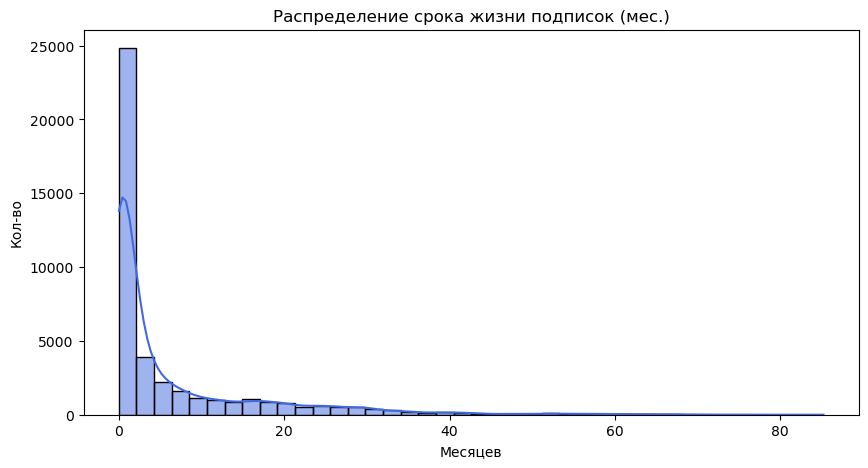

=== Показатели подписок ===
Доля регулярных пожертвований: 100%
Средняя длительность (все): 6.41 мес.
Средняя длительность (завершенные): 3.57 мес.
Медианная длительность: 1.08 мес.
Накопленная доля завершённых подписок (Terminal Status Share): 84.65%
Среднее число платежей на подписчика: 7.66
Среднее число платежей на подписку: 5.61


In [28]:
# Доля регулярных пожертвований
# В выгрузке все записи — подписки, поэтому доля регулярных = 100% внутри датасета.
share_recurring = 1.0

# Средняя длительность подписки
avg_duration_all = df_clean['duration_months'].mean()
avg_duration_churned = df_clean[df_clean['event'] == 1]['duration_months'].mean()
median_duration = df_clean['duration_months'].median()

plt.figure(figsize=(10, 5))
sns.histplot(df_clean['duration_months'], bins=40, kde=True, color='royalblue')
plt.title('Распределение срока жизни подписок (мес.)')
plt.xlabel('Месяцев')
plt.ylabel('Кол-во')
plt.show()

# Накопленная доля завершённых подписок
terminal_status_share = df_clean['event'].mean()

avg_payments_per_subscriber = df_clean['payments_count'].sum() / df_clean['payer_id'].nunique()
avg_payments_per_subscription = df_clean['payments_count'].mean()

print('=== Показатели подписок ===')
print(f'Доля регулярных пожертвований: {share_recurring:.0%}')
print(f'Средняя длительность (все): {avg_duration_all:.2f} мес.')
print(f'Средняя длительность (завершенные): {avg_duration_churned:.2f} мес.')
print(f'Медианная длительность: {median_duration:.2f} мес.')
print(f'Накопленная доля завершённых подписок (Terminal Status Share): {terminal_status_share:.2%}')
print(f'Среднее число платежей на подписчика: {avg_payments_per_subscriber:.2f}')
print(f'Среднее число платежей на подписку: {avg_payments_per_subscription:.2f}')

<font color=  #0210CF>**Промежуточные выводы**<br>
Все записи — подписки, поэтому внутри датасета доля регулярных пожертвований 100%. Для расчёта доли относительно разовых нужны данные по разовым платежам.<br>
Распределение резко правостороннее: один доминирующий пик в начале и длинный хвост вправо до ~85 месяцев.<br>
Уровень оттока высокий, что говорит о необходимости работы с первыми неделями и моментом первого сбоя списания.<br>
Среднее число платежей на подписчика выше, чем на подписку, — часть донаторов оформляет несколько подписок/перезапускает их (возможно из-за технических сложностей).<br>

| Зона распределения | Интерпретация | Рекомендация |
|---|---|---|
| **Пик 0–2 мес** | Основные потери: неуспешный первый платёж, непонимание механики автоплатежа | Welcome-цепочка, триггер при неудачном списании, напоминание о незавершённой оплате |
| **Спад 2–12 мес** | Постепенное «выгорание» подписок, включая критическое окно 3–6 мес | Отчёты о результатах помощи на 3-й и 6-й месяцы |
| **Горб ~16–18 мес** | Накопление живых недавних когорт (дек 2024 – янв 2025): удержание улучшилось | Закрепить текущие практики привлечения и онбординга |
| **Хвост 20–85 мес** | Лояльное ядро: малочисленно, но формирует основной объём | Персональное сопровождение, клуб доноров или что-то подобное |
</font>

## Анализ выживаемости подписок

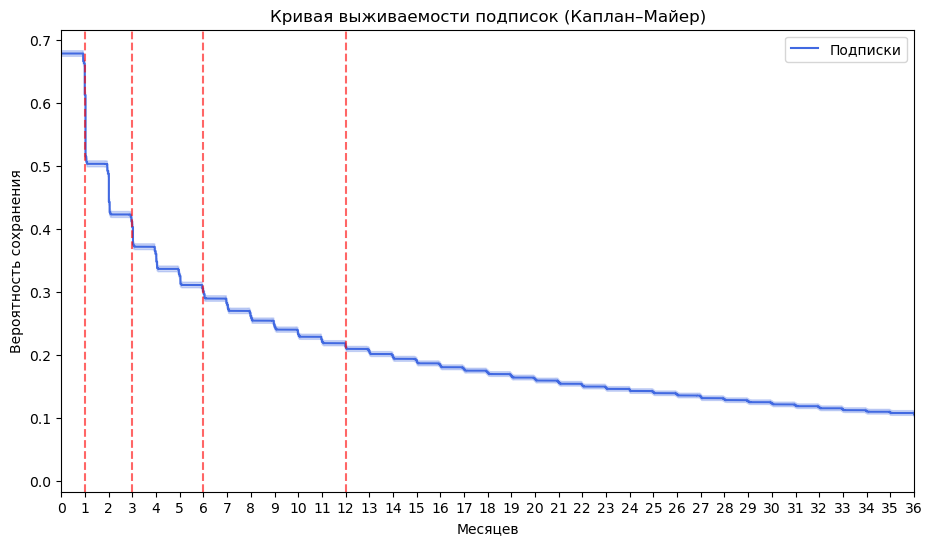

_____________________________________________
=== Анализ Выживаемости (подписка как объект) ===
Вероятность сохранения через  1 мес.: 61.22%
Вероятность сохранения через  3 мес.: 40.25%
Вероятность сохранения через  6 мес.: 30.10%
Вероятность сохранения через 12 мес.: 21.30%
_____________________________________________
Медианное время жизни подписки: 1.93824 мес.
_____________________________________________
Точки наибольшего спада выживаемости:


,День,Месяц,"Спад, %"
0,31,1.02,9.77
1,30,0.99,5.03
2,61,2.00,4.47
3,92,3.02,2.74
4,2556,83.97,2.07


_____________________________________________
=== Время успешных платежей (отдельный показатель) ===


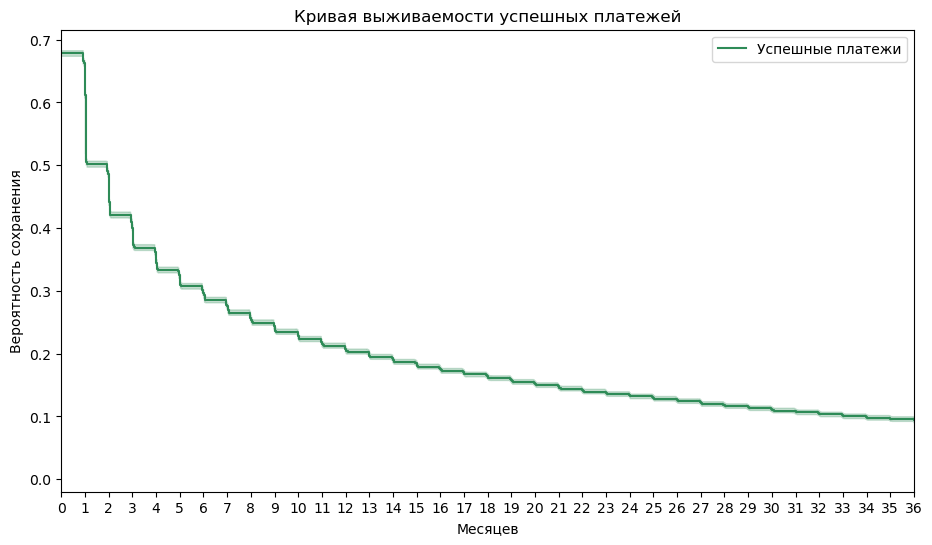

Вероятность сохранения платежей через  1 мес.: 61.18%
Вероятность сохранения платежей через  3 мес.: 40.03%
Вероятность сохранения платежей через  6 мес.: 29.71%
Вероятность сохранения платежей через 12 мес.: 20.70%
Медианное время успешных платежей: 1.93824 мес.


In [34]:
# === Survival Analysis подписки как объекта ===
# Цензурирование: для живых подписок конец = SNAPSHOT_DATE

kmf = KaplanMeierFitter()
kmf.fit(df_clean['duration_months'], event_observed=df_clean['event'], label='Подписки')

plt.figure(figsize=(11, 6))
kmf.plot_survival_function(ci_show=True, color='royalblue')
for m in [1, 3, 6, 12]:
    plt.axvline(m, color='red', linestyle='--', alpha=0.6)
plt.title('Кривая выживаемости подписок (Каплан–Майер)')
plt.xlabel('Месяцев')
plt.ylabel('Вероятность сохранения')
plt.xlim(0, 36)
plt.xticks(range(0, 37))
plt.gca().tick_params(axis='x')
plt.show()

print('_____________________________________________')
print('=== Анализ Выживаемости (подписка как объект) ===')

survival_points = kmf.predict([1, 3, 6, 12])
for m, s in zip([1, 3, 6, 12], survival_points):
    print(f'Вероятность сохранения через {m:>2} мес.: {s:.2%}')

print('_____________________________________________')

median_survival = kmf.median_survival_time_
print(f'Медианное время жизни подписки: {median_survival:.5f} мес.')

print('_____________________________________________')

# Критичные периоды ухода
surv_curve = kmf.survival_function_.copy()
surv_curve['duration_months'] = surv_curve.index
surv_curve['drop'] = surv_curve['Подписки'].diff().abs() * 100

critical_periods = (
    surv_curve.dropna()
    .nlargest(5, 'drop')[['duration_months', 'drop']]
    .copy()
)
critical_periods['days'] = (critical_periods['duration_months'] * 30.44).round(0).astype(int)

critical_periods = (
    critical_periods[['days', 'duration_months', 'drop']]
    .rename(columns={
        'days': 'День',
        'duration_months': 'Месяц',
        'drop': 'Спад, %'
    })
    .round({'Месяц': 2, 'Спад, %': 2})
    .reset_index(drop=True)
)

print('Точки наибольшего спада выживаемости:')
display(critical_periods)

# === Отдельный показатель: время успешных платежей ===
print('_____________________________________________')
print('=== Время успешных платежей (отдельный показатель) ===')

kmf_payments = KaplanMeierFitter()
kmf_payments.fit(
    df_clean['payment_duration_months'],
    event_observed=df_clean['event'],
    label='Успешные платежи'
)

plt.figure(figsize=(11, 6))
kmf_payments.plot_survival_function(ci_show=True, color='seagreen')
plt.title('Кривая выживаемости успешных платежей')
plt.xlabel('Месяцев')
plt.ylabel('Вероятность сохранения')
plt.xlim(0, 36)
plt.xticks(range(0, 37))
plt.gca().tick_params(axis='x')
plt.show()

surv_points_payments = kmf_payments.predict([1, 3, 6, 12])
for m, s in zip([1, 3, 6, 12], surv_points_payments):
    print(f'Вероятность сохранения платежей через {m:>2} мес.: {s:.2%}')

median_payment = kmf_payments.median_survival_time_
print(f'Медианное время успешных платежей: {median_payment:.5f} мес.')

<font color=  #0210CF>**Промежуточные выводы**<br>
Кривая Каплана–Майера показывает резкий спад в начале, затем более плавное снижение. Те, кто пережил первый год, остаются надолго.<br>
Вероятности сохранения через 1 / 3 / 6 / 12 месяцев (61,2% / 40,3% / 30,1% и значение 12 мес. в выводе выше) — ключевые контрольные точки для KPI фонда и контроля эффекта от будущих изменений (welcome-цепочка, триггеры при сбое и т.д.).<br>
**Посчитаны два раздельных показателя:** время жизни подписки как объекта и время успешных платежей. Медианное время успешных платежей — 1,94 мес. совпадает с Медианным временем жизни подписки, но показатели Вероятности сохранения платежей чуть меньше Вероятность сохранения подписки.
Связано с тем, что после последнего успешного платежа подписка нередко формально живёт ещё некоторое время (неудачные списания, «Просрочена») до терминального статуса. Этот разрыв — зона работы триггеров повтора платежа и обновления карты.
- Медианное время жизни подписки — ориентир для прогноза LTV и планирования.
- Точки наибольшего спада выживаемости задают приоритетные окна триггерных коммуникаций: ~30-й день (первое списание) и 2–3-й месяцы:<br>

| Период | Суммарный спад | Что это значит |
|---|---:|---|
| **0–1 месяц** | ~15% | Главный фронт потерь: первое списание  |
| **1–2 месяца** | +4,5% | Второе списание: отсев тех, кто передумал |
| **2–3 месяца** | +2,8% | Третье списание: отсев из-за отсутствия обратной связи |
| **Итого первые 3 месяца** | **~22%** | Более пятой части базы теряется до формирования привычки |
| **После 3 месяцев** | резкое падение интенсивности | Подписки, пережившие рубеж, становятся «почти вечными» |
| **84 месяца (~7 лет)** | 1,7% | Единичный естественный уход, не требует действий |
</font>
</font>

## Когортные метрики: Retention, Churn Rate, LTV

<font color=  #0210CF>Визуализацию метрики Retention смотри выше в пункте Когортный анализ — матрица удержания</font>

==== СРАВНЕНИЕ ПЕРИОДОВ ====
Весь период (среднее):
churn_rate          0.791763
avg_ltv          1781.714246
retention_3m        0.418128
retention_6m        0.311243
retention_12m       0.203759
dtype: float64

Последние 12 полных месяцев (среднее):
churn_rate          0.354619
avg_ltv          2100.112606
retention_3m        0.661931
retention_6m        0.560983
retention_12m       0.202312
dtype: float64


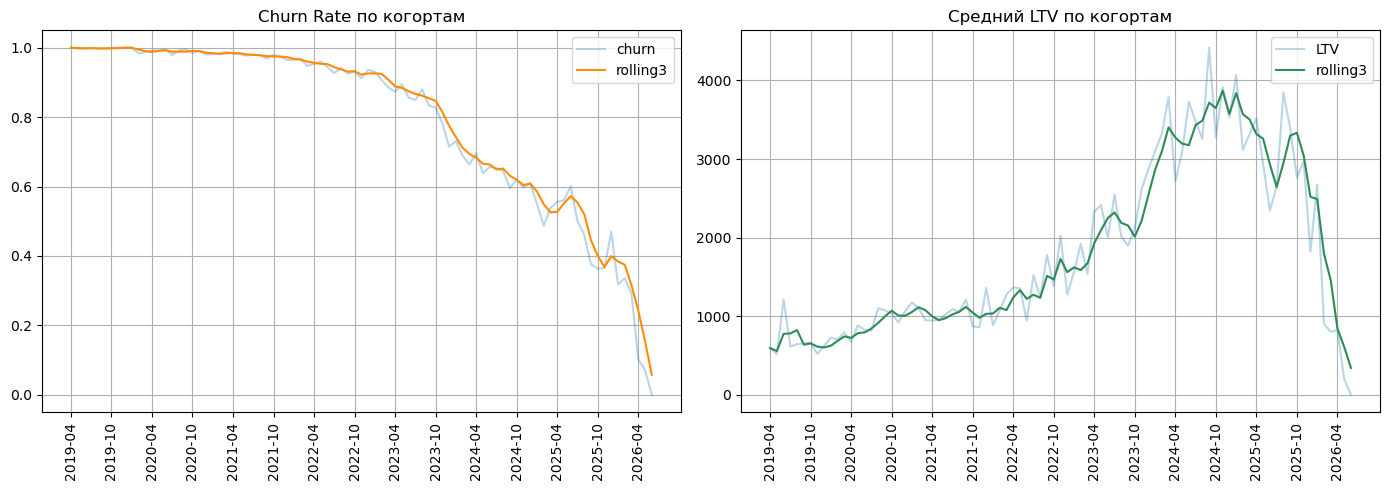

In [30]:
cohort_last12 = None

# Метрики по когортам за весь период
cohort_metrics = df_clean.groupby('cohort').agg(
    subscribers=('id', 'count'),
    churn_rate=('event', 'mean'),
    avg_ltv=('total_volume', 'mean'),
).reset_index()

# Retention на контрольных точках — только для когорт, достигших нужного возраста
for k in [3, 6, 12]:
    cohort_min_date = df_clean['cohort'] + k
    mask_mature = cohort_min_date <= SNAPSHOT_DATE.to_period('M')
    retention_k = (
        df_clean[mask_mature]
        .groupby('cohort')['duration_months']
        .apply(lambda s: (s >= k).mean())
    )
    cohort_metrics[f'retention_{k}m'] = cohort_metrics['cohort'].map(retention_k)

# === LTV на одинаковом горизонте ===
for horizon in [3, 6, 12]:
    mask_mature = (df_clean['cohort'] + horizon) <= SNAPSHOT_DATE.to_period('M')
    src = df_clean.loc[mask_mature].copy()
    src['ltv_capped'] = src['amount'] * src['payments_count'].clip(upper=horizon)
    ltv_h = src.groupby('cohort')['ltv_capped'].mean()
    cohort_metrics[f'ltv_{horizon}m'] = cohort_metrics['cohort'].map(ltv_h)

cohort_metrics = cohort_metrics.sort_values('cohort').reset_index(drop=True)

# Скользящее среднее с окном в 3 когорты
rolling_cols = ['churn_rate', 'avg_ltv', 'retention_3m', 'retention_6m', 'retention_12m']
for col in rolling_cols:
    cohort_metrics[f'{col}_rolling3'] = cohort_metrics[col].rolling(3, min_periods=1).mean()

# Сравнение периодов: весь период vs последние 12 полных месяцев
snapshot_period = SNAPSHOT_DATE.to_period('M')
last_12_periods = [snapshot_period - i for i in range(1, 13)]
cohort_last12 = cohort_metrics[cohort_metrics['cohort'].isin(last_12_periods)]

print('==== СРАВНЕНИЕ ПЕРИОДОВ ====')
print('Весь период (среднее):')
print(cohort_metrics[['churn_rate', 'avg_ltv', 'retention_3m', 'retention_6m', 'retention_12m']].mean())
print('\nПоследние 12 полных месяцев (среднее):')
print(cohort_last12[['churn_rate', 'avg_ltv', 'retention_3m', 'retention_6m', 'retention_12m']].mean())

# Визуализация скользящего среднего
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(cohort_metrics['cohort'].astype(str), cohort_metrics['churn_rate'], alpha=0.3, label='churn')
axes[0].plot(cohort_metrics['cohort'].astype(str), cohort_metrics['churn_rate_rolling3'], color='darkorange', label='rolling3')
axes[0].set_title('Churn Rate по когортам')
axes[0].grid()

axes[1].plot(cohort_metrics['cohort'].astype(str), cohort_metrics['avg_ltv'], alpha=0.3, label='LTV')
axes[1].plot(cohort_metrics['cohort'].astype(str), cohort_metrics['avg_ltv_rolling3'], color='seagreen', label='rolling3')
axes[1].set_title('Средний LTV по когортам')
axes[1].grid()

for ax in axes:
    ax.set_xticks(ax.get_xticks()[::6])
    plt.setp(ax.get_xticklabels(), rotation=90)
    ax.legend()

plt.tight_layout()
plt.show()

<font color=  #0210CF>**Интерпретация**<br>
Рассчитаны Retention, Churn Rate и LTV по когортам за весь период.<br>
Добавлено скользящее среднее для сглаживания шума в малых когортах.<br>
Сравнение «весь период vs последние 12 полных месяцев» показывает, улучшилось ли удержание и LTV в недавних когортах. Последний неполный месяц исключён, чтобы не искажать оценку.<br>
<br>
Корректное доказательство улучшения удержания — **Retention** 3 и 6 месяцев, посчитанный только по созревшим когортам: весь период 41,8% / 31,1% против последних 12 полных месяцев 66,2% / 56,1%. Оба периода сравниваются на когортах, достигших нужного возраста, поэтому сравнение корректно и подтверждает улучшение онбординга и первых списаний.<br>
<br>
**Churn Rate** по по созревшим когортам. Снижение оранжевой линии churn_rate_rolling3 к концу периода означает, что недавние когорты теряют меньше подписок. Это согласуется с теплокартой, где поздние когорты «темнее» (лучше удерживаются).<br>
<br>
**LTV** для честного сравнения когорт используются метрики на одинаковом горизонте ltv_3m / ltv_6m / ltv_12m по созревшим когортам. Рост зелёной линии avg_ltv_rolling3 означает, что каждая новая когорта в среднем приносит больше денег — за счёт лучшего удержания и/или роста среднего чека.<br>
<br>
**Сравнение периодов**. Если «последние 12 месяцев» лучше «всего периода» по retention_3m/6m и churn — текущие практики привлечения и онбординга работают, их стоит закрепить и масштабировать.
</font>

## ABC-анализ и Парето-анализ

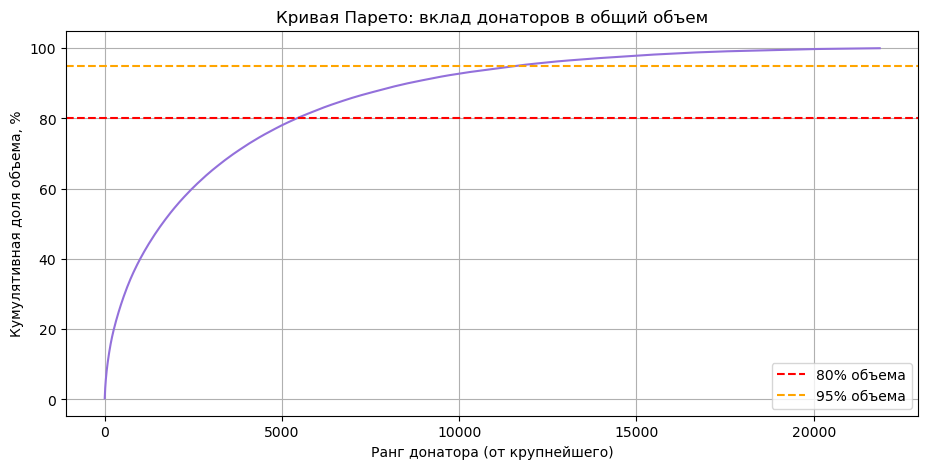

____________________________________________________________

==== ABC / ПАРЕТО ====


,abc_group,donors,volume,volume_share,donors_share
0,A,5411,59300956.00,0.799967,0.247484
1,B,6207,11121512.00,0.150029,0.283891
2,C,10246,3706785.82,0.050004,0.468624


___________________________________________________

==== Топ-10 донаторов =====


,payer_id,total_volume,cumulative_share
0,PID_0c805ad28c0f,235500.0,0.003177
1,PID_7baae73ac7f2,200000.0,0.005875
2,PID_7658d88f2574,180000.0,0.008303
3,PID_2f1f912f078a,180000.0,0.010731
4,PID_08f50d5b2763,177500.0,0.013126
5,PID_23a12e15c6db,177500.0,0.015520
6,PID_5e5e0d59a806,173500.0,0.017861
7,PID_0c172162b1fc,170000.0,0.020154
8,PID_a27a0a09768f,160500.0,0.022319
9,PID_b7dcbc21a198,150000.0,0.024343


In [31]:
# Согласно Q&A: для Парето выбросы (крупные донаторы) возвращаем -> используем df_clean (без тестовых)
pareto_src = df_clean[df_clean['payments_count'] > 0]

donor_volume = pareto_src.groupby('payer_id')['total_volume'].sum().reset_index()
donor_volume = donor_volume.sort_values('total_volume', ascending=False).reset_index(drop=True)
donor_volume['cumulative_volume'] = donor_volume['total_volume'].cumsum()
donor_volume['cumulative_share'] = donor_volume['cumulative_volume'] / donor_volume['total_volume'].sum()

# ABC-группы по вкладу в объем: A ~80%, B ~15%, C ~5%
def assign_abc(share):
    if share <= 0.80:
        return 'A'
    elif share <= 0.95:
        return 'B'
    return 'C'

donor_volume['abc_group'] = donor_volume['cumulative_share'].apply(assign_abc)

abc_summary = donor_volume.groupby('abc_group').agg(
    donors=('payer_id', 'count'),
    volume=('total_volume', 'sum')
).reset_index()
abc_summary['volume_share'] = abc_summary['volume'] / abc_summary['volume'].sum()
abc_summary['donors_share'] = abc_summary['donors'] / abc_summary['donors'].sum()


# Кривая Парето
plt.figure(figsize=(11, 5))
plt.plot(donor_volume.index, donor_volume['cumulative_share'] * 100, color='mediumpurple')
plt.axhline(80, color='red', linestyle='--', label='80% объема')
plt.axhline(95, color='orange', linestyle='--', label='95% объема')
plt.title('Кривая Парето: вклад донаторов в общий объем')
plt.xlabel('Ранг донатора (от крупнейшего)')
plt.ylabel('Кумулятивная доля объема, %')
plt.legend()
plt.grid()
plt.show()

print('____________________________________________________________')
print('\n==== ABC / ПАРЕТО ====')
display(abc_summary)

top_n = donor_volume.head(10)
print('___________________________________________________')
print('\n==== Топ-10 донаторов =====')
display(top_n[['payer_id', 'total_volume', 'cumulative_share']])

<font color=  #0210CF>**Интерпретация результатов:**<br>
Для ABC-анализа cчитаем по каждой группе:<br>
сколько донаторов (donors);<br>
сколько денег они принесли (volume);<br>
долю группы в объёме (volume_share);<br>
долю группы в базе (donors_share).<br>
<br>

| Группа | Диапазон кумулятивной доли | Смысл |
|---|---|---|
| **A** | 0–80% | Донаторы, которые вместе дают 80% объёма |
| **B** | 80–95% | Дают следующие 15% объёма |
| **C** | 95–100% | Дают последние 5% объёма |

</font>

<font color=  #0210CF>**Оценка кривой Парето:**<br>
Кривая имеет плавный, логарифмический вид без резкого «локтя»: она круто поднимается в первой четверти базы, но затем долго и постепенно добирает остаток. Это говорит о умеренной концентрации объема пожертвований — в фонде нет узкой группы «китов», которая единолично держит весь бюджет; вклад распределён относительно широко.<br>
То есть вместо канонического «20% донаторов дают 80% денег» здесь скорее «25–27% донаторов дают 80%», а последние ~45% базы приносят лишь ~5% объема.
<br>
| Контрольная точка | Ранг пересечения | Доля базы (~22 тыс. донаторов) |
|---|---:|---:|
| 80% объема (граница A/B) | ≈ 5 500–6 000 | ≈ 25–27% |
| 95% объема (граница B/C) | ≈ 11 500–12 000 | ≈ 52–55% |
| 100% объема | ≈ 21 800 | 100% |
</font>

<font color=  #0210CF>**Рекомендации:**<br>
Риск концентрации умеренный. Отсутствие сверхкрутого «локтя» — это плюс для устойчивости фонда: потеря одного крупного донатора не обрушит бюджет. Но группа A всё равно критична — четверть базы держит 80% денег.<br>
Группа A требует приоритетного внимания: персональные отчёты, клуб доноров, ручное сопровождение, контроль статуса их подписок (триггер при Просрочена).<br>
Группа B — главный резерв роста. Плавный изгиб кривой означает, что между B и A нет жёсткой стены: апсейл суммы подписки и вовлечение в адресные сборы могут переводить донаторов из B в A.<br>
Группа C — только автоматизированные коммуникации (триггерные и контентные рассылки): работать с ней вручную экономически нецелесообразно, но это «питательная среда» будущих донаторов групп B и A.<br>

## Повторные пожертвования, интервалы и жизненный цикл донатора

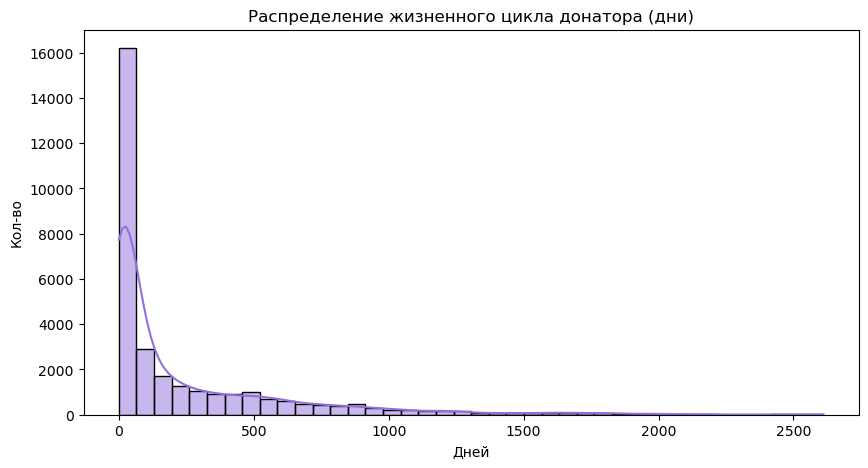

___________________________________________________
==== ПОВТОРНЫЕ ПОЖЕРТВОВАНИЯ И ЖИЗНЕННЫЙ ЦИКЛ ====
 
Доля донаторов с несколькими подписками: 18.08%
Среднее число подписок на донатора: 1.37
Средний интервал между платежами: 45.1 дней
Медианный интервал между платежами: 38.0 дней
Средний жизненный цикл донатора: 245 дней
Медианный жизненный цикл донатора: 61 дней
___________________________________________________
==== ПРОПУЩЕННЫЕ МЕСЯЦЫ (метрика риска) ====
 


,missed_segment,subscriptions,total_volume_at_risk,avg_months_missed,volume_share
0,0 пропусков (регулярно),178,1246990.00,0.000000,0.016822
1,1 пропуск (первый риск),3139,20036365.00,0.481068,0.270290
2,2 пропуска (высокий риск),758,5459214.00,1.482732,0.073645
3,3+ пропуска (вероятный отток),38420,47386684.82,44.715565,0.639244


In [32]:
# Повторные подписки
subs_per_donor = df_clean.groupby('payer_id')['id'].count()
repeat_donors = (subs_per_donor > 1).mean()
avg_subs_per_donor = subs_per_donor.mean()

# Интервалы между платежами
intervals_src = df_clean[df_clean['payments_count'] > 1].copy()
intervals_src['avg_interval_days'] = (
    (intervals_src['last_payment_date'] - intervals_src['created_at']).dt.days
    / (intervals_src['payments_count'] - 1)
)
avg_interval = intervals_src['avg_interval_days'].mean()
median_interval = intervals_src['avg_interval_days'].median()

# Жизненный цикл донатора
donor_lifecycle = df_clean.groupby('payer_id').agg(
    first_created=('created_at', 'min'),
    last_activity=('last_payment_date', 'max'),
    total_volume=('total_volume', 'sum')
).reset_index()
donor_lifecycle['lifecycle_days'] = (donor_lifecycle['last_activity'] - donor_lifecycle['first_created']).dt.days
avg_lifecycle = donor_lifecycle['lifecycle_days'].mean()
median_lifecycle = donor_lifecycle['lifecycle_days'].median()

plt.figure(figsize=(10, 5))
sns.histplot(donor_lifecycle['lifecycle_days'], bins=40, kde=True, color='mediumpurple')
plt.title('Распределение жизненного цикла донатора (дни)')
plt.xlabel('Дней')
plt.ylabel('Кол-во')
plt.show()

print('___________________________________________________')
print('==== ПОВТОРНЫЕ ПОЖЕРТВОВАНИЯ И ЖИЗНЕННЫЙ ЦИКЛ ====')
print(' ')
print(f'Доля донаторов с несколькими подписками: {repeat_donors:.2%}')
print(f'Среднее число подписок на донатора: {avg_subs_per_donor:.2f}')
print(f'Средний интервал между платежами: {avg_interval:.1f} дней')
print(f'Медианный интервал между платежами: {median_interval:.1f} дней')
print(f'Средний жизненный цикл донатора: {avg_lifecycle:.0f} дней')
print(f'Медианный жизненный цикл донатора: {median_lifecycle:.0f} дней')

# === Метрика пропущенных месяцев ===
print('___________________________________________________')
print('==== ПРОПУЩЕННЫЕ МЕСЯЦЫ (метрика риска) ====')
print(' ')
missed_summary = df_clean.groupby('missed_segment').agg(
    subscriptions=('id', 'count'),
    total_volume_at_risk=('total_volume', 'sum'),
    avg_months_missed=('months_missed', 'mean')
).reset_index()
missed_summary['volume_share'] = missed_summary['total_volume_at_risk'] / missed_summary['total_volume_at_risk'].sum()
display(missed_summary)

<font color=  #0210CF>**Интерпретация:**<br>
Медианный жизненный цикл мал — половина донаторов взаимодействует с фондом коротко (оформил — сделал 1–2 платежа — ушёл).<br>
Средний жизненный цикл больше медианы из-за длинного хвоста: небольшая группа донаторов остаётся на годы и формирует основной вклад (согласуется с правилом Парето).<br>
Доноры, у которых жизненный цикл существенно длиннее срока одной подписки, — это те, кто возвращается после пауз. Именно на них работают реактивационные кампании.<br>

| Зона | Инсайт | Действие |
|---|---|---|
| **Повторные донаторы (18%)** | Донаторы возвращаются, реактивация работает | Закрепить практики, масштабировать win-back кампании |
| **Интервал 38–45 дней** | У большинства — ежемесячно, но сбои растягивают среднее | Триггер при статусе `Просрочена`, напоминание о неудачном списании |
| **Медианный цикл 61 день** | Половина донаторов уходит за 2 месяца | Welcome-цепочка, отчёт на 3-й месяц, объяснение автоплатежа |
| **Средний цикл 245 дней** | Длинный хвост лояльных формирует LTV | Персональное сопровождение ядра, клуб доноров |

</font>

<font color=  #0210CF>**Рекомендации:**<br>
Для «хрупкого старта» (0–60 дней): максимальные усилия на первые 2 месяца — welcome-цепочка, триггер при первом сбое, объяснение механики автоплатежа.<br>
Для работы с интервалами: разрыв медиана/среднее показывает, что сбои платежей — системная проблема. Триггерное письмо при Просрочена с просьбой обновить карту может сократить этот разрыв и увеличить медианный интервал до ~31 дня.<br>
Для повторных донаторов (18%): эти люди уже доказали лояльность. Их стоит сегментировать отдельно — предлагать апсейл суммы, вовлекать в адресные сборы, приглашать в клуб доноров.<br>
Для долгосрочного ядра: донаторы с жизненным циклом > 12 месяцев — это основа LTV и Парето-группы A. Их потеря критична, поэтому требуется персональное сопровождение.<br>
</font>

## Сводная таблица рекомендаций

| Направление | Инсайт из анализа | Практическая рекомендация | Метрика контроля |
|---|---|---|---|
| **1. Увеличение регулярных пожертвований** | Часть подписок не проходит первый успешный платеж или быстро переходит в статусы `Отклонена` / `Отменена`. Донор может не завершить оплату, не понять механику автоплатежа или испугаться регулярных списаний. | Усилить onboarding после оформления подписки: welcome-письмо с благодарностью, объяснением ежемесячного списания и рассказом, как помощь будет использоваться. Добавить письмо-напоминание для незавершенных платежей и статуса ожидания аутентификации. | Доля подписок с первым успешным платежом; конверсия из оформления в активную подписку; доля подписок со вторым и третьим платежом; доля подписок с `payments_count = 0` как диагностика проблемы первого платежа. |
| **2. Повышение удержания донаторов** | Критические периоды ухода: первый месяц после оформления (момент первого списания), момент первого неудачного списания и период 3–6 месяцев, когда донор начинает оценивать прозрачность и результат помощи. | Настроить триггерные email-цепочки: уведомление о неудачном списании с просьбой обновить карту; письмо через 2–3 недели после подписки с историей помощи; отчеты на 3-й и 6-й месяц. Для статуса `Просрочена` отправлять автоматическое сообщение до перехода в `Отклонена`. | Churn Rate; Retention через 1, 3, 6 и 12 месяцев; доля подписок, восстановленных после неудачного списания. |
| **3. Увеличение средней продолжительности подписки** | Survival-анализ показывает, что значительная часть подписок завершается на раннем этапе; при этом есть устойчивые долгосрочные подписки с 12–18 и более платежами. | Развивать привычку регулярной помощи: персональные отчеты, истории подопечных, напоминания о результатах. Добавить возможность легко изменить сумму или дату списания вместо полной отмены. При отмене предлагать паузу или уменьшение суммы. | Средняя и медианная длительность подписки; доля подписок дольше 3, 6 и 12 месяцев; количество измененных вместо отмены подписок. |
| **4. Рост долгосрочной ценности донатора, LTV** | ABC/Pareto-анализ показывает, что небольшая часть донаторов формирует основной объем пожертвований (~25–27% базы дают 80% объема). Также выделяются сегменты лояльных донаторов и ценных донаторов с риском ухода. | Выделить отдельное сопровождение для крупных донаторов (≥ 10 000 ₽/мес — отдельный сегмент, чтобы не искажать средние) и наиболее ценных донаторов: персональные отчеты, индивидуальная коммуникация, приглашения к адресным сборам. Для сегмента уходящих ценных донаторов запускать реактивационные письма с предложением обновить платежные данные или выбрать комфортный формат помощи. | Средний LTV по когортам; средний доход на активного донатора; доля возвращенных ценных донаторов; объем пожертвований по сегменту A. |
| **5. Работа с причинами оттока** | В данных видны подписки с нулевым числом платежей, быстрые отмены и подписки, остановленные после нескольких неудачных списаний. Фонду важно понимать, отмена связана с техническим сбоем или с осознанным решением донора. | Добавить короткий опрос при отмене подписки: «Почему вы отменили подписку?» с вариантами: неудобно, нет возможности, не понял результат, техническая ошибка, другое. Анализировать ответы отдельно по сегментам и причинам. | Количество заполненных опросов; доля отмен по причинам; снижение оттока после изменений. |
| **6. Сегментация коммуникаций** | RFM-анализ позволяет выделить ключевые сегменты: Новые, Чемпионы (лояльные), Уходящие ценные, Спящие, а также крупных донаторов. Массовые рассылки без сегментации могут быть недостаточно эффективны. | Перейти от массовых рассылок к сегментным: новым донорам — welcome-цепочка; чемпионам — отчеты и благодарность; уходящим ценным — реактивация; спящим — адресный сбор с понятной целью; крупным — персональное сопровождение. | Открытия и клики по сегментным рассылкам; конверсия в повторный платеж; churn по сегментам; рост частоты платежей. |
| **7. Контроль сезонности и внешних периодов** | Возможны сезонные колебания: перераспределение личных бюджетов в конце года, снижение активности в отдельные месяцы и рост внимания во время адресных сборов. | Планировать удерживающие кампании заранее перед периодами возможного спада. В периоды активного привлечения — контролировать качество первых платежей и не допускать роста технических отмен. | Помесячная динамика активных подписок; сезонный churn; retention новых когорт. |

**Приоритетные первые шаги:**<br>
Настроить триггерное письмо при неудачном списании и статусе Просрочена.<br>
Запустить welcome-цепочку для новых подписчиков.<br>
Добавить отчетные письма на 3-й и 6-й месяц жизни подписки.<br>
Внедрить короткий опрос при отмене подписки.<br>
Выделить сегменты крупных и «Уходящих ценных» донаторов (55% платящей базы) для отдельной коммуникации и запустить реактивацию.<br>